Description...

In [1]:
import sys
sys.path.append('/lhome/ific/c/ccortesp/Analysis/')

from libs import crudo

from   iminuit import Minuit
from   iminuit.cost import LeastSquares
from matplotlib.gridspec import GridSpec
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd
from   scipy.optimize import curve_fit
from   scipy.signal import find_peaks
import scipy.stats
import yaml

# Styling Plot
# crudo.pt.papers_plot_style()
crudo.pt.ccortesp_plot_style()
# PRELIM_LOGO = np.asarray(Image.open('/lhome/ific/c/ccortesp/Analysis/images/next_logo_preliminary.png'))

%matplotlib inline
%load_ext autoreload
%autoreload 2

# Runs Configuration

In [66]:
RUNS_TO_CHECK = [14739, 16153]
# RUNS_TO_CHECK = [14739, 16122, 16123]
EXTRA_TAG = None      # Options: None, '20260727', 'prod_cuts'
CRITERIA  = 'Xe'      # Options: 'Ar', 'Xe', 'Xe_vN'
ALPHA_CUT = 1200
WIDTH_CUT = 0.5

RUNS_INFO_FILENAME = "/lhome/ific/c/ccortesp/Analysis/NEXT-100/Cmmssnng/utilities/runs_information.csv"
BASE_PATH = '/lhome/ific/c/ccortesp/Data/Cmmssnng/h5/'

In [67]:
RUNS_INFO_DF = pd.read_csv(RUNS_INFO_FILENAME, index_col="run_number").reset_index()
RUNS_INFO_DF = RUNS_INFO_DF[RUNS_INFO_DF["run_number"].isin(RUNS_TO_CHECK)].copy()
RUNS_INFO_DF

,run_number,pressure,cath_voltage,gate_voltage,duration,OK,LOST,isotope
2,14739,3.956,22997.3,7501.1,87138.0,2576630.0,2334343.0,Xe
20,16153,8.879,32996.9,9401.6,NaN,NaN,NaN,Xe


# Selected Data

In [68]:
SEL_DICT = {}

print('Loading selected data for:')
for run_id in RUNS_INFO_DF['run_number']:

    # Construct a clean, descriptive dictionary key
    key = f"{run_id}_v{EXTRA_TAG}" if EXTRA_TAG is not None else f"{run_id}"
    print(f"  - Run {key}")

    # Load and assign the data
    doro_df = pd.read_hdf(os.path.join(BASE_PATH, 'run_' + key + '_selected_' + CRITERIA + '.h5'), key='DST/Events')
    # soph_df = pd.read_hdf(os.path.join(BASE_PATH, 'run_' + key + '_selected_' + CRITERIA + '.h5'), key='RECO/Events')

    SEL_DICT[key] = {}
    SEL_DICT[key]['doro_df'] = doro_df
    # SEL_DICT[key]['soph_df'] = soph_df

Loading selected data for:
  - Run 14739
  - Run 16153


Construct the _active volume_ mask to avoid the cathode

In [69]:
EXTRA_INFO = {}
for key in SEL_DICT.keys():

    print(f"\nRun {key}:")
    doro_df = SEL_DICT[key]['doro_df']

    cath_lim = crudo.tf.get_cathode_limit(doro_df, n_bins=80, step_back=0)
    # cath_lim = doro_df['DT'].max()
    z_mask    = (doro_df['DT'] >= 0) & (doro_df['DT'] < cath_lim)
    cath_mask = (doro_df['DT'] >= cath_lim)
    alpha_mask = (doro_df['S1e_corr'] > ALPHA_CUT)

    low_width = (doro_df['S1w'] / 1e3 < WIDTH_CUT)
    high_width = (doro_df['S1w'] / 1e3 >= WIDTH_CUT)

    EXTRA_INFO[key] = { 'cath_lim': cath_lim, 'AV_Z_mask': z_mask, 'cath_mask': cath_mask, 'alpha_mask': alpha_mask, 'low_width': low_width, 'high_width': high_width }


Run 14739:
Cathode limit = 1331.51 μs

Run 16153:
Cathode limit = 1480.73 μs


# Base Distributions (WITH CUTS!)

### Radial


Run 16153:
  - R² (low width)  = [1.88, 238016.85] mm²
  - R² (high width) = [19.90, 258616.51] mm²


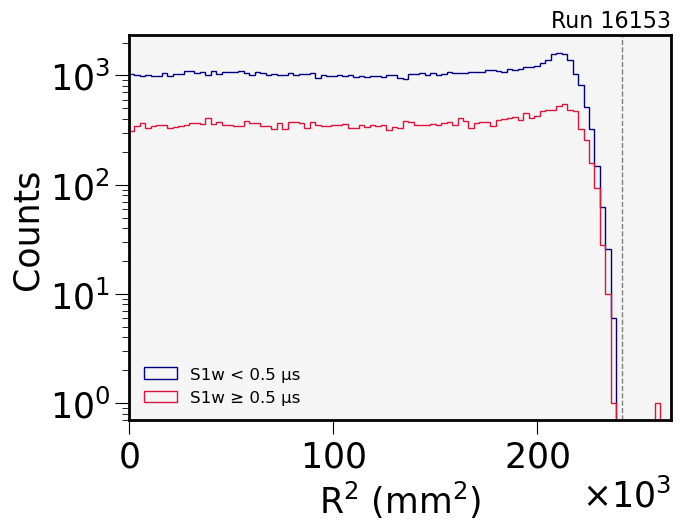

In [6]:
bins = np.linspace(0, 1.1*crudo.pt.N100_rad**2, 100)

for key in SEL_DICT.keys():

    print(f"\nRun {key}:")
    doro_df = SEL_DICT[key]['doro_df']

    # Variables
    R2 = doro_df['X']**2 + doro_df['Y']**2

    # Masks
    alpha_mask  = EXTRA_INFO[key]['alpha_mask']
    low_w_mask  = EXTRA_INFO[key]['low_width']
    high_w_mask = EXTRA_INFO[key]['high_width']

    R2_low  = R2[alpha_mask & low_w_mask]
    R2_high = R2[alpha_mask & high_w_mask]
    print(f"  - R² (low width)  = [{R2_low.min():.2f}, {R2_low.max():.2f}] mm²")
    print(f"  - R² (high width) = [{R2_high.min():.2f}, {R2_high.max():.2f}] mm²")

    c_low, _, _  = plt.hist(R2_low, bins=bins, histtype='step', color='navy', lw=1.0, label='S1w < 0.5 μs')
    c_high, _, _ = plt.hist(R2_high, bins=bins, histtype='step', color='crimson', lw=1.0, label='S1w ≥ 0.5 μs')

    # Plot
    plt.xlabel('R$^{2}$ (mm$^{2}$)')
    plt.ylabel('Counts')
    plt.yscale('log')
    plt.xlim(bins[0], bins[-1])
    plt.ticklabel_format(axis='x', style='sci', scilimits=(3, 3))
    plt.legend(loc='lower left', fontsize=12)
    plt.title(f'Run {key}', loc='right', fontsize=16)

    # Radial line
    plt.axvline(x=crudo.pt.N100_rad**2, c='gray', ls='--', lw=1)

    plt.gca().set_facecolor("whitesmoke")
    plt.show()

### ΔT


Run 14739:
  - DT (low width)  = [nan, nan] μs
  - DT (high width) = [24.13, 1613.95] μs


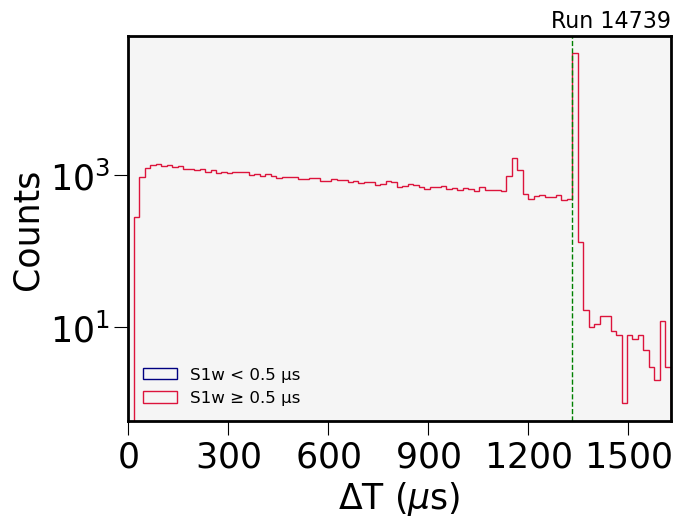


Run 16153:
  - DT (low width)  = [23.88, 1586.76] μs
  - DT (high width) = [24.21, 1622.71] μs


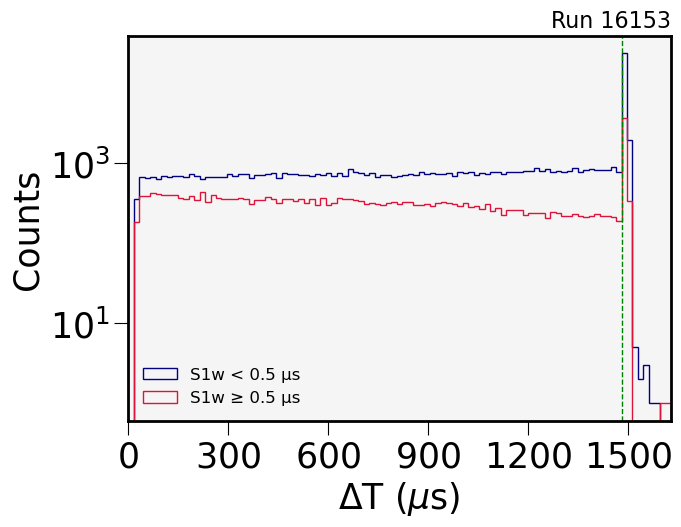

In [71]:
bins = np.linspace(0, 1.1*EXTRA_INFO[key]['cath_lim'], 100)

for key in SEL_DICT.keys():

    print(f"\nRun {key}:")
    doro_df = SEL_DICT[key]['doro_df']
    cath_lim = EXTRA_INFO[key]['cath_lim']

    # Variables
    DT = doro_df['DT']

    # Masks
    alpha_mask  = EXTRA_INFO[key]['alpha_mask']
    low_w_mask  = EXTRA_INFO[key]['low_width']
    high_w_mask = EXTRA_INFO[key]['high_width']

    DT_low  = DT[alpha_mask & low_w_mask]
    DT_high = DT[alpha_mask & high_w_mask]
    print(f"  - DT (low width)  = [{DT_low.min():.2f}, {DT_low.max():.2f}] μs")
    print(f"  - DT (high width) = [{DT_high.min():.2f}, {DT_high.max():.2f}] μs")

    c_low, _, _  = plt.hist(DT_low, bins=bins, histtype='step', color='navy', lw=1.0, label='S1w < 0.5 μs')
    c_high, _, _ = plt.hist(DT_high, bins=bins, histtype='step', color='crimson', lw=1.0, label='S1w ≥ 0.5 μs')

    # Plot
    plt.xlabel('$\Delta$T ($\mu$s)')
    plt.ylabel('Counts')
    plt.yscale('log')
    plt.xlim(bins[0], bins[-1])
    plt.xticks(np.arange(0, bins[-1], 300))
    # plt.ticklabel_format(axis='x', style='sci', scilimits=(3, 3))
    plt.legend(loc='lower left', fontsize=12)
    plt.title(f'Run {key}', loc='right', fontsize=16)

    # Cathode line
    plt.axvline(x=EXTRA_INFO[key]['cath_lim'], c='green', ls='--', lw=1)

    plt.gca().set_facecolor("whitesmoke")
    plt.show()

### $S1e$


Run 14739:
  - E1 (low width)  = [nan, nan] PE
  - E1 (high width) = [1200.05, 123250.96] PE


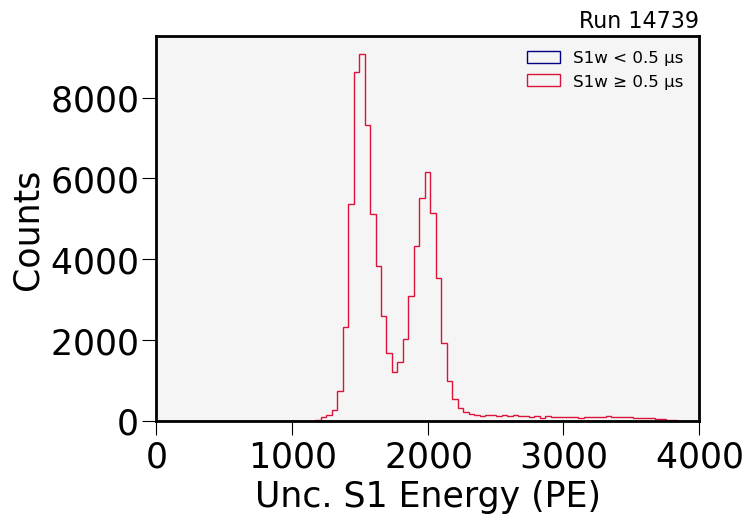


Run 16153:
  - E1 (low width)  = [1204.05, 5336.80] PE
  - E1 (high width) = [1203.41, 5252.16] PE


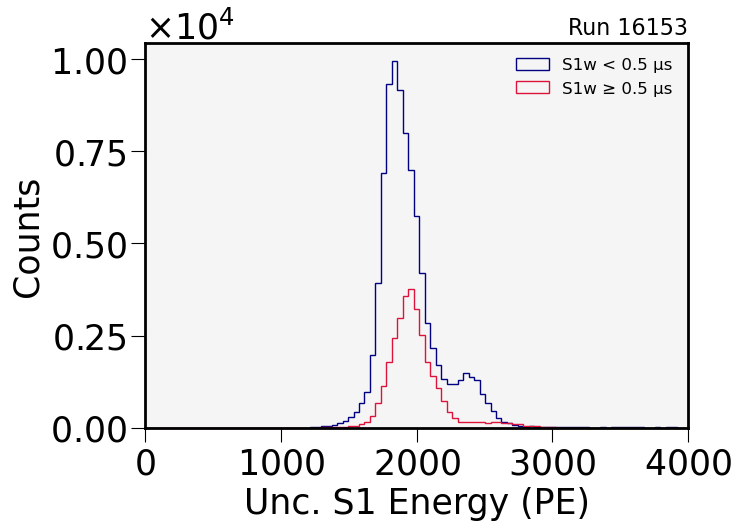

In [81]:
# Params
bins = np.linspace(0, 4e3, 100)

for key in SEL_DICT.keys():

    print(f"\nRun {key}:")
    doro_df = SEL_DICT[key]['doro_df']

    # Variables
    E1 = doro_df['S1e_corr']
    W2 = doro_df['S2w']

    # Masks
    alpha_mask  = EXTRA_INFO[key]['alpha_mask']
    low_w_mask  = EXTRA_INFO[key]['low_width']
    high_w_mask = EXTRA_INFO[key]['high_width']

    E1_low  = E1[alpha_mask & low_w_mask & (W2 > 60)]
    E1_high = E1[alpha_mask & high_w_mask & (W2 > 60)]
    print(f"  - E1 (low width)  = [{E1_low.min():.2f}, {E1_low.max():.2f}] PE")
    print(f"  - E1 (high width) = [{E1_high.min():.2f}, {E1_high.max():.2f}] PE")

    c_low, _, _  = plt.hist(E1_low, bins=bins, histtype='step', color='navy', lw=1.0, label='S1w < 0.5 μs')
    c_high, _, _ = plt.hist(E1_high, bins=bins, histtype='step', color='crimson', lw=1.0, label='S1w ≥ 0.5 μs')

    # Plot
    plt.xlabel('Unc. S1 Energy (PE)')
    plt.ylabel('Counts')
    # plt.yscale('log')
    plt.xlim(bins[0], bins[-1])
    plt.ticklabel_format(axis='x', style='sci', scilimits=(0, 4))
    plt.legend(loc='upper right', fontsize=12)
    plt.title(f'Run {key}', loc='right', fontsize=16)

    # Cut line
    # plt.axvline(x=850, c='gray', ls='--', lw=1)
    # plt.axvline(x=4e3, c='gray', ls='--', lw=1)

    plt.gca().set_facecolor("whitesmoke")
    plt.show()

### $S2e$


Run 14739:
  - E2 (low width)  = [nan, nan] PE
  - E2 (high width) = [46645.24, 2271222.25] PE


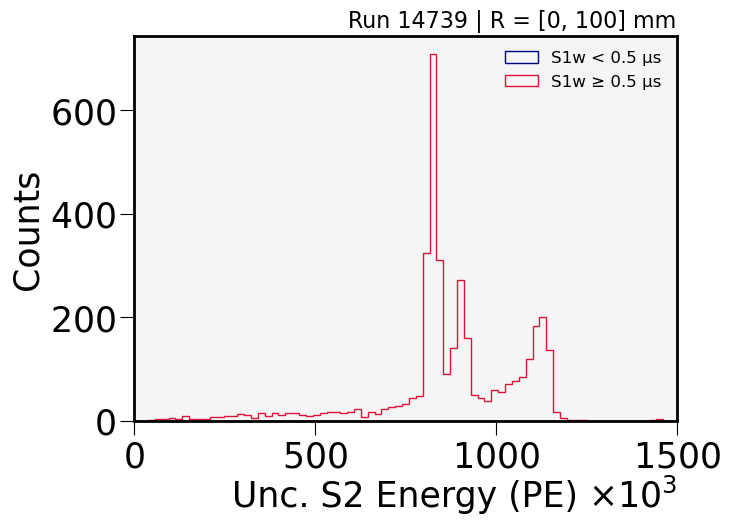

  - E2 (low width)  = [nan, nan] PE
  - E2 (high width) = [45741.44, 2010271.62] PE


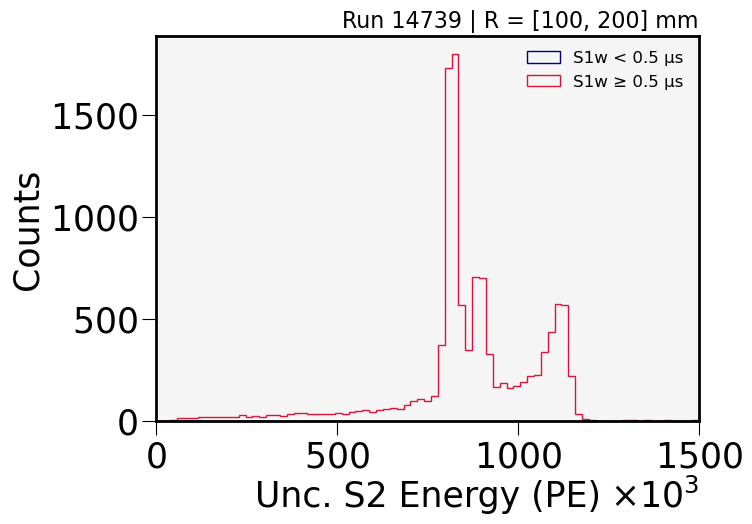

  - E2 (low width)  = [nan, nan] PE
  - E2 (high width) = [43005.29, 2108717.00] PE


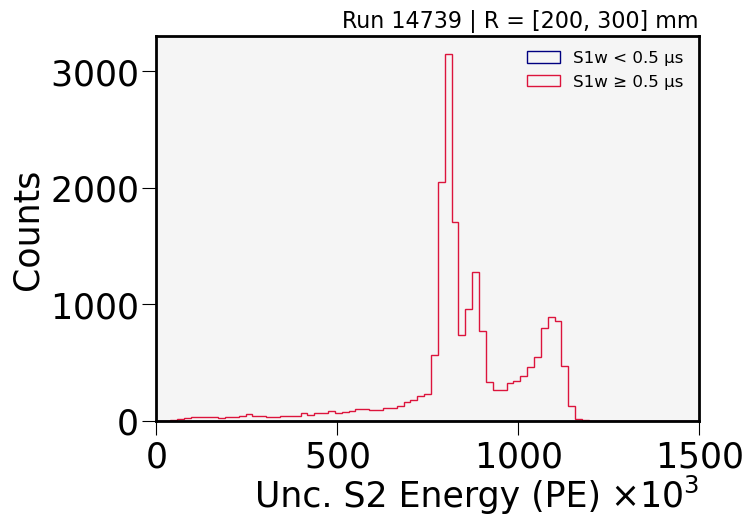

  - E2 (low width)  = [nan, nan] PE
  - E2 (high width) = [42736.73, 1876760.88] PE


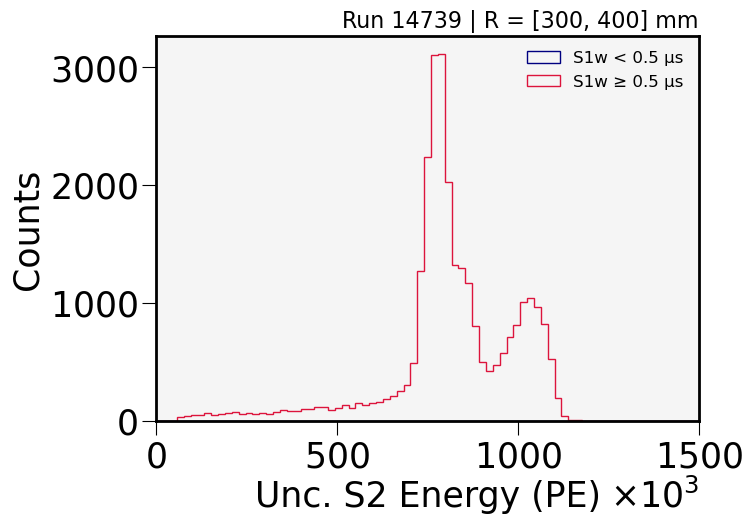

  - E2 (low width)  = [nan, nan] PE
  - E2 (high width) = [40059.92, 1678932.62] PE


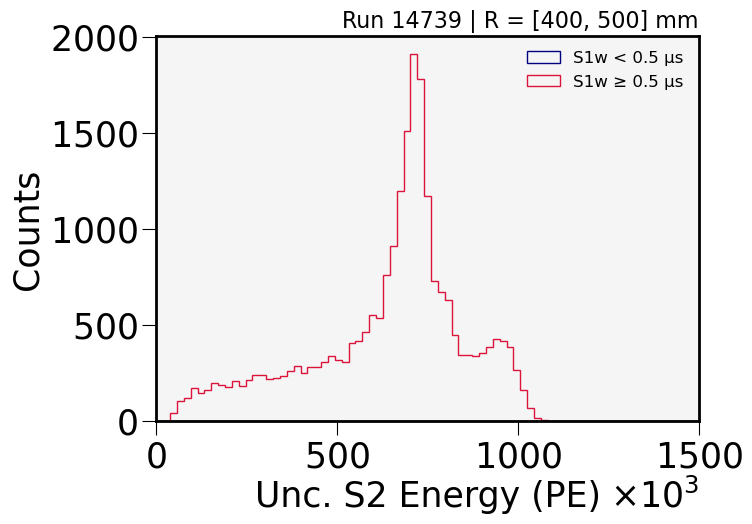


Run 16153:
  - E2 (low width)  = [40040.71, 966392.00] PE
  - E2 (high width) = [51136.59, 680266.50] PE


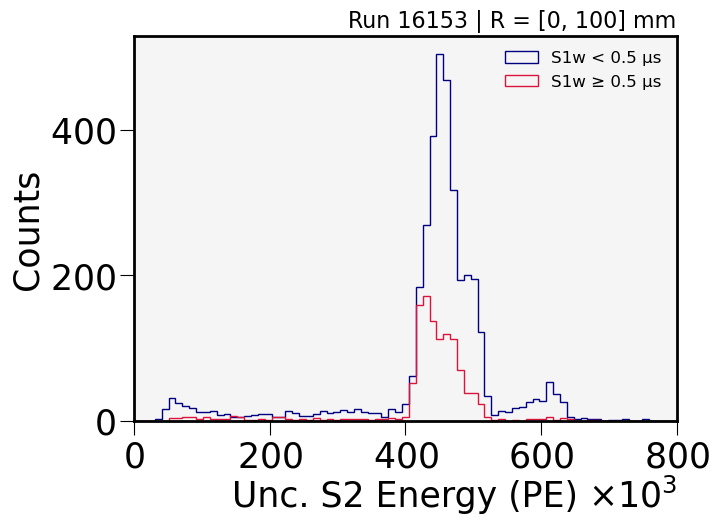

  - E2 (low width)  = [40071.32, 877918.75] PE
  - E2 (high width) = [40881.20, 891877.38] PE


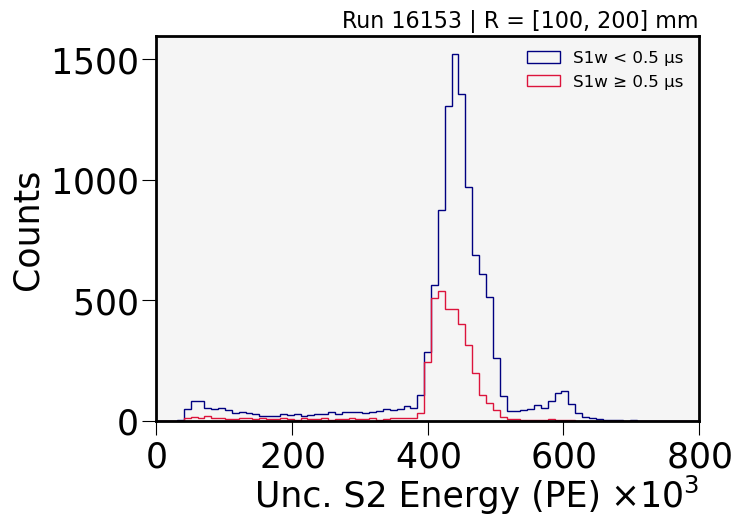

  - E2 (low width)  = [40047.91, 867107.25] PE
  - E2 (high width) = [41790.70, 659363.38] PE


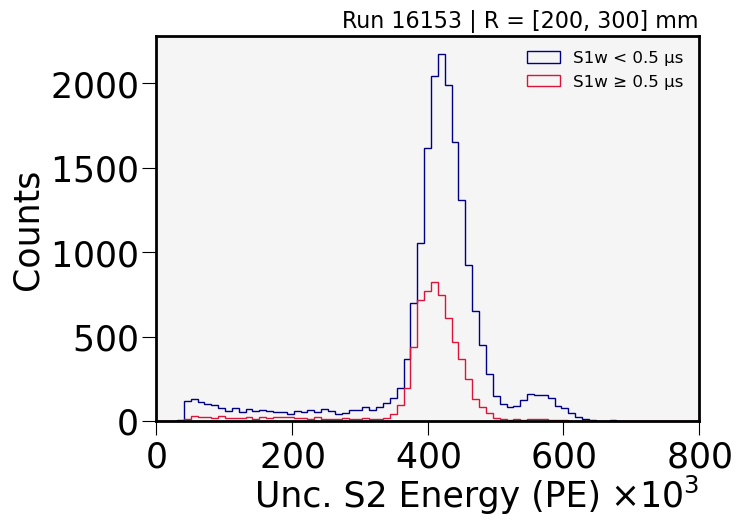

  - E2 (low width)  = [40124.08, 768463.62] PE
  - E2 (high width) = [40251.08, 750510.31] PE


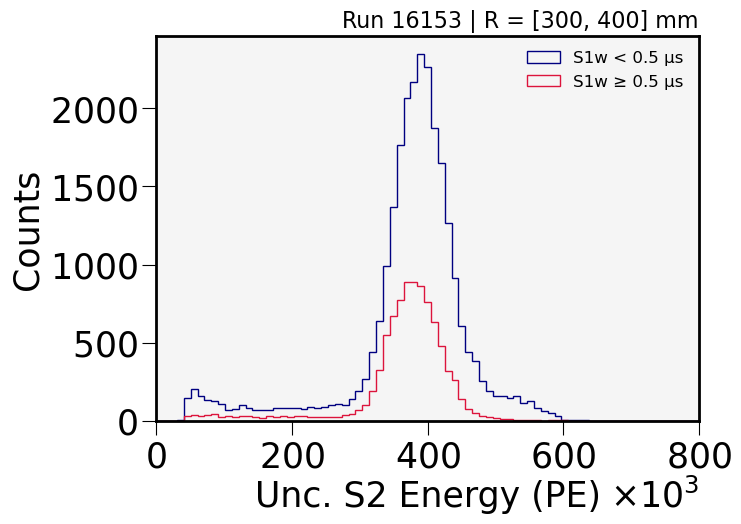

  - E2 (low width)  = [40005.30, 725691.12] PE
  - E2 (high width) = [40234.09, 591464.38] PE


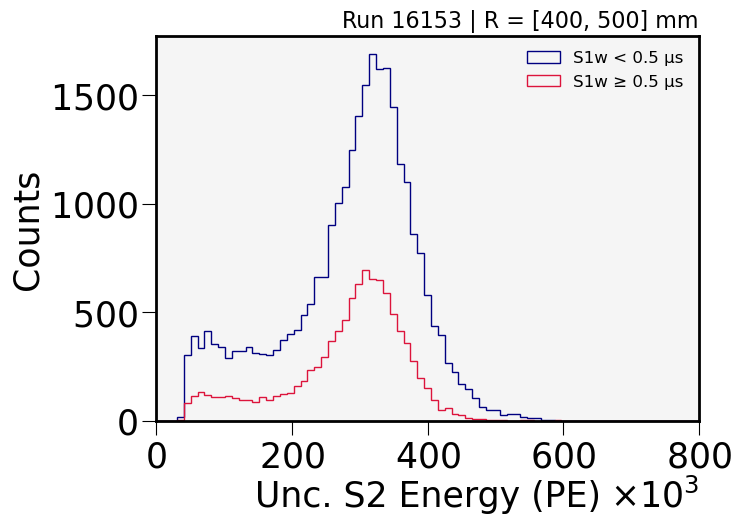

In [80]:
# Params

r_lims = [100, 200, 300, 400, 500]

for key in SEL_DICT.keys():

    print(f"\nRun {key}:")
    run_id = int(key.split('_')[0])
    doro_df = SEL_DICT[key]['doro_df']

    if run_id == 14739:  bins = np.linspace(0, 1500e3, 80)
    elif run_id == 16153: bins = np.linspace(0, 800e3, 80)

    # Variables
    E2 = doro_df['S2e']
    R  = doro_df['R']
    W2 = doro_df['S2w']

    # Masks
    alpha_mask  = EXTRA_INFO[key]['alpha_mask']
    low_w_mask  = EXTRA_INFO[key]['low_width']
    high_w_mask = EXTRA_INFO[key]['high_width']

    for i, rad_lim in enumerate(r_lims):

        r_min = 0 if i == 0 else r_lims[i-1]
        rad_mask = (R >= r_min) & (R <= rad_lim) & (W2 >= 60)

        E2_low  = E2[alpha_mask & low_w_mask  & rad_mask]
        E2_high = E2[alpha_mask & high_w_mask & rad_mask]
        print(f"  - E2 (low width)  = [{E2_low.min():.2f}, {E2_low.max():.2f}] PE")
        print(f"  - E2 (high width) = [{E2_high.min():.2f}, {E2_high.max():.2f}] PE")

        c_low, _, _  = plt.hist(E2_low, bins=bins, histtype='step', color='navy', lw=1.0, label='S1w < 0.5 μs')
        c_high, _, _ = plt.hist(E2_high, bins=bins, histtype='step', color='crimson', lw=1.0, label='S1w ≥ 0.5 μs')

        # Plot
        plt.xlabel('Unc. S2 Energy (PE)')
        plt.ylabel('Counts')
        # plt.yscale('log')
        plt.xlim(bins[0], bins[-1])
        plt.ticklabel_format(axis='x', style='sci', scilimits=(3, 3))
        plt.legend(loc='upper right', fontsize=12)
        plt.title(f'Run {key} | R = [{r_min}, {rad_lim}] mm', loc='right', fontsize=16)

        # Cut line
        # plt.axvline(x=5e3, c='gray', ls='--', lw=1)

        plt.gca().set_facecolor("whitesmoke")
        plt.show()

### $S2w$


Run 14739:
  - W2 (low width)  = [nan, nan] μs
  - W2 (high width) = [10.15, 194.00] μs


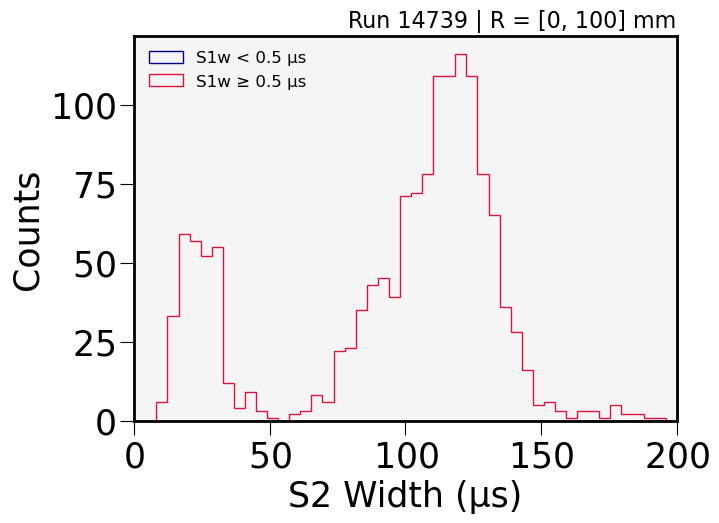

  - W2 (low width)  = [nan, nan] μs
  - W2 (high width) = [10.22, 198.40] μs


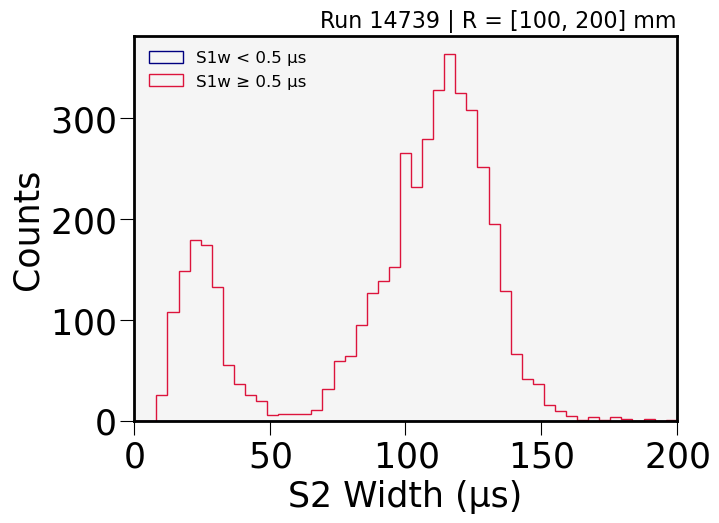

  - W2 (low width)  = [nan, nan] μs
  - W2 (high width) = [10.00, 200.00] μs


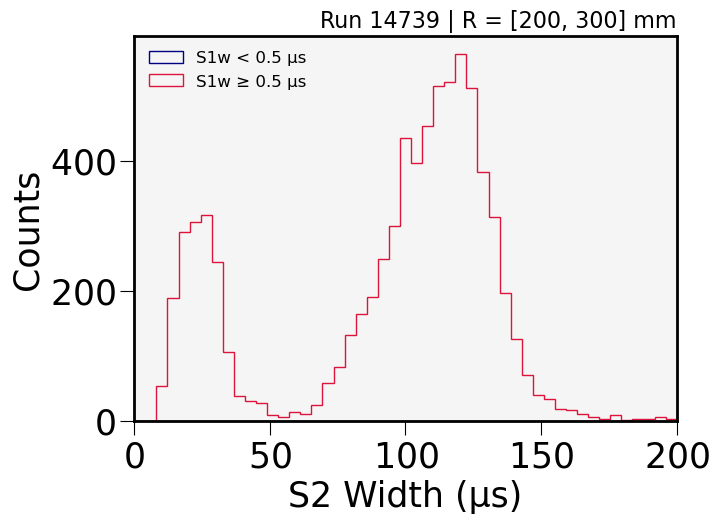

  - W2 (low width)  = [nan, nan] μs
  - W2 (high width) = [10.05, 200.00] μs


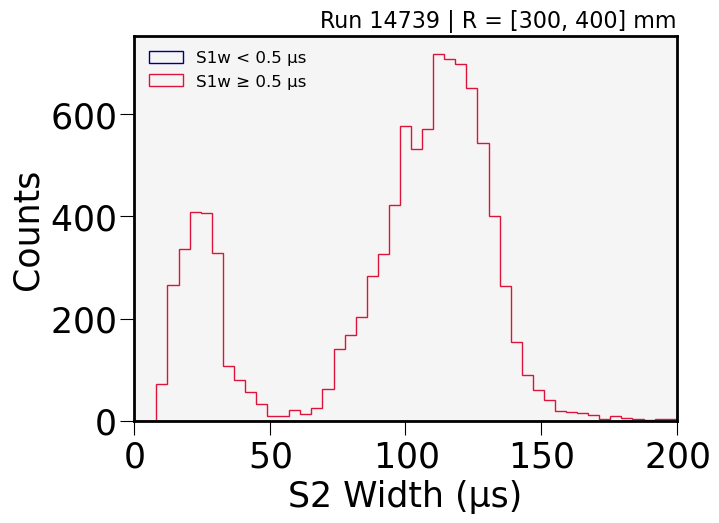

  - W2 (low width)  = [nan, nan] μs
  - W2 (high width) = [10.00, 200.00] μs


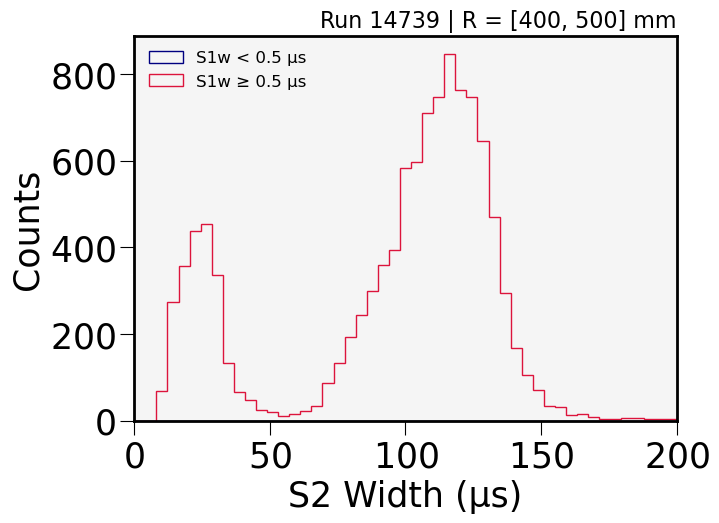


Run 16153:
  - W2 (low width)  = [17.12, 144.68] μs
  - W2 (high width) = [24.10, 132.10] μs


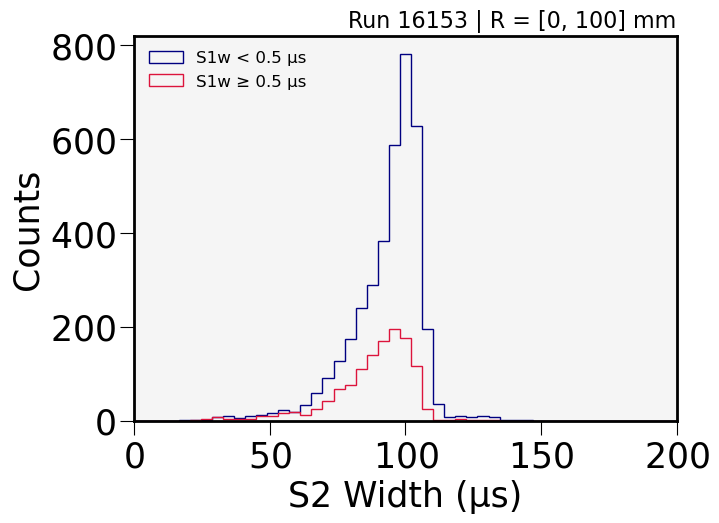

  - W2 (low width)  = [16.73, 156.38] μs
  - W2 (high width) = [20.05, 141.57] μs


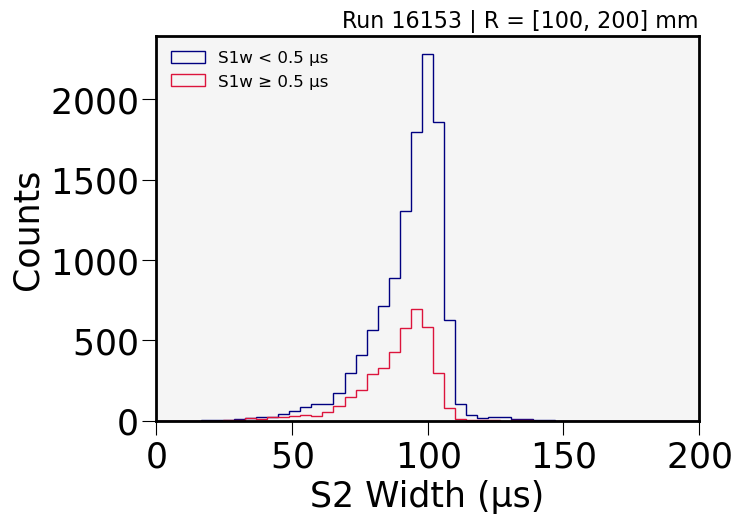

  - W2 (low width)  = [14.27, 193.55] μs
  - W2 (high width) = [22.75, 146.55] μs


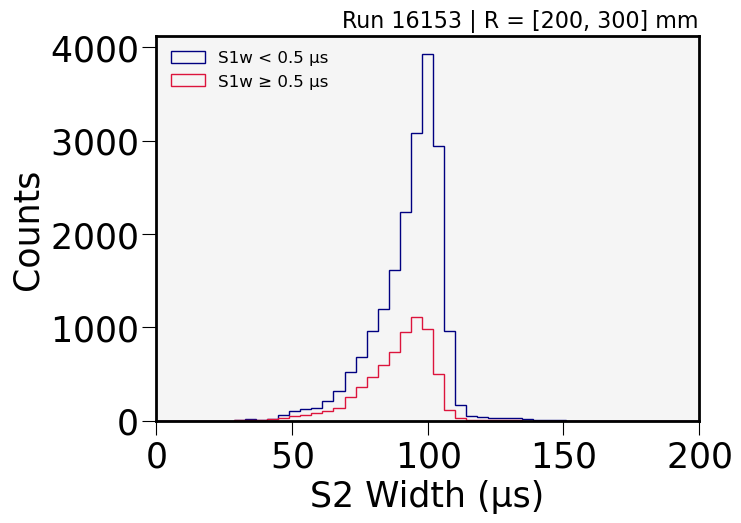

  - W2 (low width)  = [10.75, 179.15] μs
  - W2 (high width) = [11.48, 144.65] μs


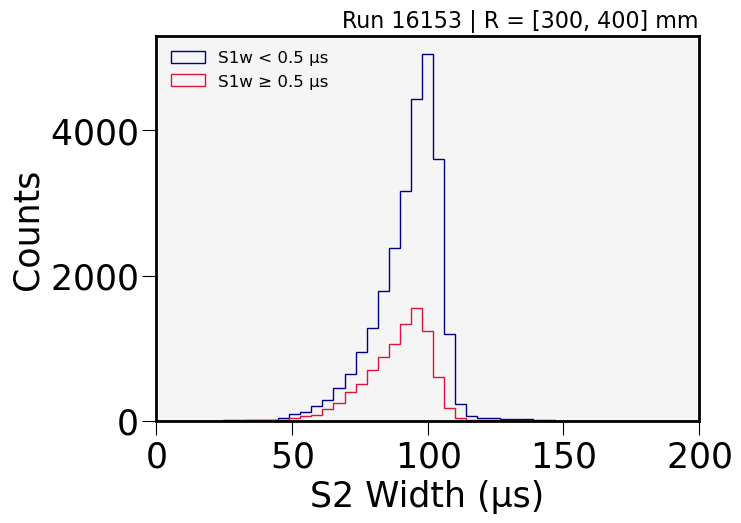

  - W2 (low width)  = [18.80, 185.55] μs
  - W2 (high width) = [19.10, 143.02] μs


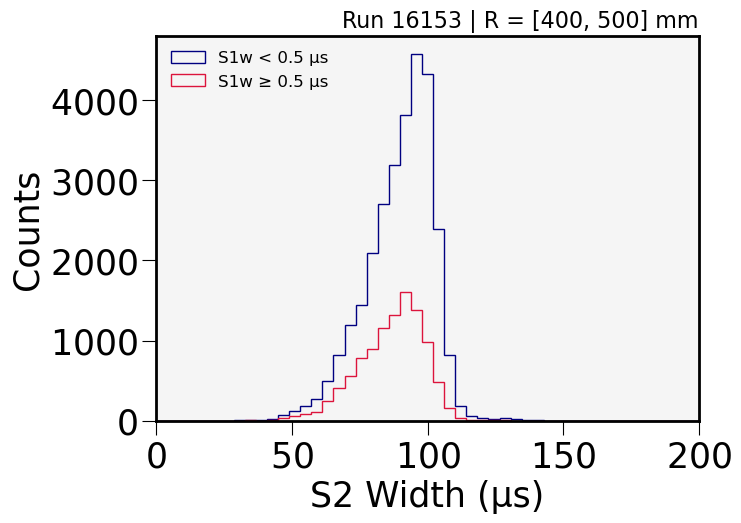

In [79]:
# Params
bins = np.linspace(0, 200, 50)
r_lims = [100, 200, 300, 400, 500]

for key in SEL_DICT.keys():

    print(f"\nRun {key}:")
    doro_df = SEL_DICT[key]['doro_df']

    # Variables
    W2 = doro_df['S2w']

    # Masks
    alpha_mask  = EXTRA_INFO[key]['alpha_mask']
    low_w_mask  = EXTRA_INFO[key]['low_width']
    high_w_mask = EXTRA_INFO[key]['high_width']

    for i, rad_lim in enumerate(r_lims):

        r_min = 0 if i == 0 else r_lims[i-1]
        rad_mask = (R >= r_min) & (R <= rad_lim)

        W2_low  = W2[alpha_mask & low_w_mask & rad_mask]
        W2_high = W2[alpha_mask & high_w_mask & rad_mask]
        print(f"  - W2 (low width)  = [{W2_low.min():.2f}, {W2_low.max():.2f}] μs")
        print(f"  - W2 (high width) = [{W2_high.min():.2f}, {W2_high.max():.2f}] μs")

        c_low, _, _  = plt.hist(W2_low, bins=bins, histtype='step', color='navy', lw=1.0, label='S1w < 0.5 μs')
        c_high, _, _ = plt.hist(W2_high, bins=bins, histtype='step', color='crimson', lw=1.0, label='S1w ≥ 0.5 μs')

        # Plot
        plt.xlabel('S2 Width (μs)')
        plt.ylabel('Counts')
        # plt.yscale('log')
        plt.xlim(bins[0], bins[-1])
        plt.legend(loc='upper left', fontsize=12)
        plt.title(f'Run {key} | R = [{r_min}, {rad_lim}] mm', loc='right', fontsize=16)

        # Cut line
        # plt.axvline(x=5e3, c='gray', ls='--', lw=2)

        plt.gca().set_facecolor("whitesmoke")
        plt.show()

# 2D Histograms

In [11]:
# # Params
# r_lims = [100, 200, 300, 400, 500]

# for key in SEL_DICT.keys():

#   print(f"\nRun {key}:")
#   doro_df = SEL_DICT[key]["doro_df"]

#   # Variables
#   E2 = doro_df["S2e"]
#   DT = doro_df["DT"]
#   R = doro_df["R"]

#   # Masks
#   base_mask = EXTRA_INFO[key]["AV_Z_mask"] & EXTRA_INFO[key]["alpha_mask"]
#   low_w_mask = EXTRA_INFO[key]["low_width"]
#   high_w_mask = EXTRA_INFO[key]["high_width"]

#   e2_min, e2_max = 100e3, 700e3
#   dt_bins = np.linspace(0, DT.max(), 50)
#   e2_bins = np.linspace(e2_min, e2_max, 40)
#   bin_centers = (dt_bins[:-1] + dt_bins[1:]) / 2

#   for i, rad_lim in enumerate(r_lims):
#     r_min = 0 if i == 0 else r_lims[i - 1]
#     rad_mask = (R >= r_min) & (R <= rad_lim)

#     mask_low = base_mask & rad_mask & low_w_mask
#     mask_high = base_mask & rad_mask & high_w_mask

#     DT_low, E2_low = DT[mask_low], E2[mask_low]
#     DT_high, E2_high = DT[mask_high], E2[mask_high]

#     if len(DT_low) < 50 or len(DT_high) < 50:
#       print(f"  [!] Skipping R = [{r_min}, {rad_lim}] mm (Low statistics)")
#       continue

#     # 2D Histograms
#     map_low, _, _ = np.histogram2d(DT_low, E2_low, bins=[dt_bins, e2_bins])
#     map_low = np.ma.masked_where(map_low == 0, map_low)

#     map_high, _, _ = np.histogram2d(DT_high, E2_high, bins=[dt_bins, e2_bins])
#     map_high = np.ma.masked_where(map_high == 0, map_high)

#     # --- Median Profiles
#     med_e2_low, _, _ = scipy.stats.binned_statistic(
#         DT_low, E2_low, statistic="median", bins=dt_bins
#     )
#     med_e2_high, _, _ = scipy.stats.binned_statistic(
#         DT_high, E2_high, statistic="median", bins=dt_bins
#     )

#     def robust_error(x):
#       if len(x) < 5:
#         return np.nan
#       iqr = np.percentile(x, 75) - np.percentile(x, 25)
#       sigma_robust = iqr / 1.349
#       return (1.2533 * sigma_robust) / np.sqrt(len(x))

#     err_e2_low, _, _ = scipy.stats.binned_statistic(
#         DT_low, E2_low, statistic=robust_error, bins=dt_bins
#     )
#     err_e2_high, _, _ = scipy.stats.binned_statistic(
#         DT_high, E2_high, statistic=robust_error, bins=dt_bins
#     )

#     # Ratio of Medians
#     with np.errstate(divide="ignore", invalid="ignore"):
#       e2_ratio = med_e2_high / med_e2_low
#       ratio_err = e2_ratio * np.sqrt(
#           (err_e2_high / med_e2_high) ** 2 + (err_e2_low / med_e2_low) ** 2
#       )

#     # --- Plotting
#     fig = plt.figure(figsize=(36, 6))
#     gs = GridSpec(2, 3, figure=fig, height_ratios=[3, 1], hspace=0.05)

#     # Panel 1: Low Width 2D (Normalized to its own max)
#     ax1 = fig.add_subplot(gs[:, 0])
#     im1 = ax1.pcolormesh(
#         dt_bins,
#         e2_bins,
#         map_low.T,
#         cmap="plasma",
#         shading="auto",
#         vmin=0,
#         vmax=map_low.max(),  # <--- NORMALIZADO A SU PROPIO MÁXIMO
#     )
#     fig.colorbar(im1, ax=ax1, label="Counts")
#     ax1.set_xlabel("$\\Delta$T ($\\mu$s)")
#     ax1.set_ylabel("Unc. S2 Energy (PE)")
#     ax1.set_title("S1w < 0.5 $\mu$s", loc="right", fontsize=16)
#     ax1.set_facecolor("whitesmoke")
#     ax1.ticklabel_format(axis="y", style="sci", scilimits=(3, 3))

#     # Panel 2: High Width 2D (Normalized to its own max)
#     ax2 = fig.add_subplot(gs[:, 1], sharex=ax1, sharey=ax1)
#     im2 = ax2.pcolormesh(
#         dt_bins,
#         e2_bins,
#         map_high.T,
#         cmap="plasma",
#         shading="auto",
#         vmin=0,
#         vmax=map_high.max(),  # <--- NORMALIZADO A SU PROPIO MÁXIMO
#     )
#     fig.colorbar(im2, ax=ax2, label="Counts")
#     ax2.set_xlabel("$\\Delta$T ($\\mu$s)")
#     ax2.set_ylabel("Unc. S2 Energy (PE)")
#     ax2.set_title("S1w ≥ 0.5 $\mu$s", loc="right", fontsize=16)
#     ax2.set_facecolor("whitesmoke")
#     ax2.ticklabel_format(axis="y", style="sci", scilimits=(3, 3))

#     # Panel 3A (Top Right): Medians with Errorbars
#     ax3_top = fig.add_subplot(gs[0, 2], sharex=ax1)
#     ax3_top.errorbar(
#         bin_centers,
#         med_e2_low,
#         yerr=err_e2_low,
#         fmt="-o",
#         color="navy",
#         label="S1w < 0.5 $\mu$s",
#         lw=1.0,
#         ms=3,
#     )
#     ax3_top.errorbar(
#         bin_centers,
#         med_e2_high,
#         yerr=err_e2_high,
#         fmt="-s",
#         color="crimson",
#         label="S1w ≥ 0.5 $\mu$s",
#         lw=1.0,
#         ms=3,
#     )
#     ax3_top.set_ylabel("Median S2e (PE)")
#     ax3_top.ticklabel_format(axis="y", style="sci", scilimits=(3, 3))
#     ax3_top.legend(loc="upper right", fontsize=12)
#     ax3_top.set_facecolor("whitesmoke")
#     plt.setp(ax3_top.get_xticklabels(), visible=False)

#     # Panel 3B (Bottom Right): Ratio Sub-panel
#     ax3_bot = fig.add_subplot(gs[1, 2], sharex=ax1)
#     ax3_bot.errorbar(
#         bin_centers, e2_ratio, yerr=ratio_err, fmt="-^", color="black", lw=1, ms=3
#     )
#     ax3_bot.axhline(1.0, color="gray", linestyle=":", lw=1)
#     ax3_bot.set_xlabel("$\\Delta$T ($\\mu$s)")
#     ax3_bot.set_ylabel("Ratio (high/low)", fontsize=14)
#     ax3_bot.set_ylim(0.9, 1.1)
#     ax3_bot.set_facecolor("whitesmoke")

#     fig.suptitle(
#         f"Run {key} | R = [{r_min}, {rad_lim}] mm",
#         fontsize=25,
#         x=0.05,
#         y=1.02,
#         ha="left",
#     )
#     plt.tight_layout()
#     plt.show()

# Two Populations

In [20]:
for key in SEL_DICT.keys():

    print(f"\nRun {key}:")
    doro_df = SEL_DICT[key]['doro_df']

    # Masks
    alpha_mask  = EXTRA_INFO[key]['alpha_mask']
    low_w_mask  = EXTRA_INFO[key]['low_width']
    high_w_mask = EXTRA_INFO[key]['high_width']

    low_df = doro_df[alpha_mask & low_w_mask].copy()
    high_df = doro_df[alpha_mask & high_w_mask].copy()

    SEL_DICT[key]['low_df'] = low_df
    SEL_DICT[key]['high_df'] = high_df


Run 16153:


# Energy Corrections

In [25]:
# Store fits information
FIT_PARAMETERS = {key: {'low':{}, 'high':{}} for key in SEL_DICT.keys()}
FIT_PARAMETERS

{'16153': {'low': {}, 'high': {}}}

## Fits

### Light Collection

Run 16153:
Fit: m = (0.66 ± 0.00) PE/μs, b = (978.52 ± 2.77) PE
     χ² / ndof = 2.67


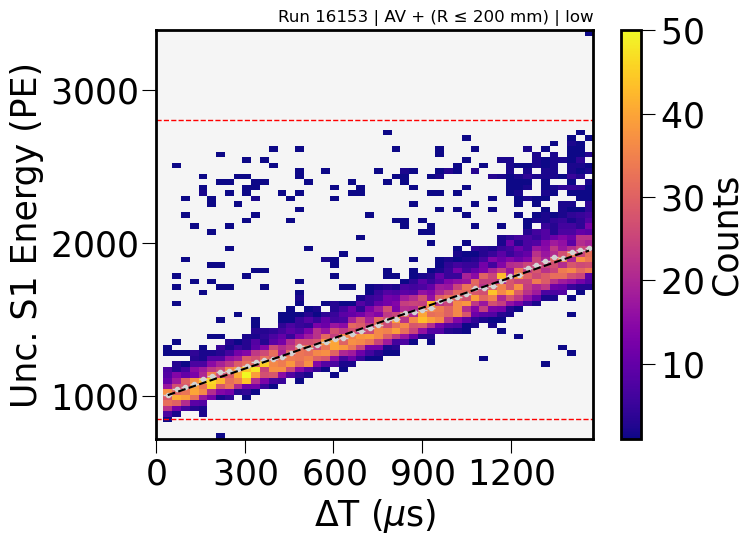

Fit: m = (0.68 ± 0.00) PE/μs, b = (1001.52 ± 2.75) PE
     χ² / ndof = 1.38


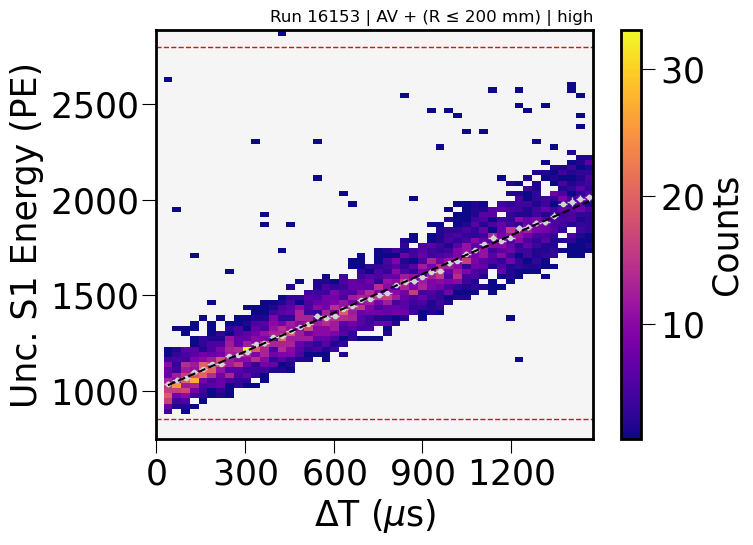

In [26]:
# Global
rad_lim = 200
e1_lim  = 4e3

# Fit region
DT_down = 0;    DT_up = 1500
# E1_down = 850;  E1_up = 2.8e3

for key in SEL_DICT.keys():

    print(f"Run {key}:")
    run_id = int(key.split('_')[0])
    cath_lim = EXTRA_INFO[key]['cath_lim']

    for width_type in ['low', 'high']:

        temp_df = SEL_DICT[key][width_type + '_df'] 

        # Variables    
        E1 = temp_df['S1e']
        DT = temp_df['DT']
        R  = temp_df['R']

        # Masking
        mask = (DT >= 0) & (DT < cath_lim) & (R <= rad_lim) & (E1 < e1_lim)
        E1_mask  = E1[mask]
        DT_mask  = DT[mask]

        # 2D histogram
        S1e_DT_map, ex, ey = crudo.pt.hist_2D(DT_mask, E1_mask, x_bins=50, y_bins=75)                       
        S1e_DT_map         = np.ma.masked_where(S1e_DT_map==0, S1e_DT_map)

        # ----- Linear Fit ----- #
        DT_up = DT_mask.max()
        if   run_id == 16057:  E1_down = 0;  E1_up = 250
        elif run_id == 14739:  E1_down = 650;  E1_up = 1.8e3
        else:
            E1_down = 850;    E1_up = 2.8e3
        # Preliminary
        DT_up = DT_mask.max()

        # Filter the data for the fit
        fit_region_mask = (DT_mask >= DT_down) & (DT_mask <= DT_up) & \
                        (E1_mask >= E1_down) & (E1_mask <= E1_up)
        DT_fit = DT_mask[fit_region_mask]
        E1_fit = E1_mask[fit_region_mask]

        # Compute representative values for the fit
        DT_centers, DT_errors, S1e_means, S1e_errors = crudo.ff.prefit_2D(DT_fit, E1_fit, bins=ex)
        # Filter out points with zero error (bins with 1 event)
        valid_points = S1e_errors > 0
        DT_centers = DT_centers[valid_points];      DT_errors  = DT_errors[valid_points]
        S1e_means  = S1e_means[valid_points];       S1e_errors = S1e_errors[valid_points]

        # Definte the cost function + initial guess
        least_squares = LeastSquares(DT_centers, S1e_means, S1e_errors, crudo.ff.linear_func)
        init_guess = [10, S1e_means.min()]
        # print(f'\nInitial guess: m = {init_guess[0]:.4f} PE/μs, b = {init_guess[1]:.4f} PE')

        # Define the Minuit object
        m = Minuit(least_squares, *init_guess)

        # Minimization process of the cost function and error estimation
        m.migrad()
        m.hesse()

        # Results
        popt = m.values;  perr = m.errors
        print(f'Fit: m = ({popt[0]:.2f} ± {perr[0]:.2f}) PE/μs, b = ({popt[1]:.2f} ± {perr[1]:.2f}) PE')    
        FIT_PARAMETERS[key][width_type]["S1e"] = {"m_CV": popt[0], "m_err": perr[0], "b_CV": popt[1], "b_err": perr[1]}

        # Reduced chi-square
        chi2 = m.fval
        ndof = len(DT_centers) - m.nfit
        print(f"     χ² / ndof = {chi2 / ndof:.2f}")

        # ----- Plotting ----- #
        plt.figure(figsize=(8, 6))
        # Data
        plt.pcolormesh(ex, ey, S1e_DT_map.T, cmap='plasma', shading='auto')    
        cbar = plt.colorbar(label='Counts', shrink=1.0)
        # cbar.formatter.set_powerlimits((-3, -3))

        # Fit
        fit_y = crudo.ff.linear_func(DT_centers, *popt)
        plt.errorbar(DT_centers, S1e_means, xerr=DT_errors, yerr=S1e_errors, fmt='o', c='lightgray', ecolor='lightgray', lw=1.0, markersize=3)
        plt.plot(DT_centers, fit_y, c='black', ls='--', lw=1.5, zorder=3)
        plt.axhline(y=E1_up, c='red', ls='--')
        plt.axhline(y=E1_down, c='red', ls='--')

        # ----- Styling ----- #
        plt.xlabel('$\Delta$T ($\mu$s)')
        plt.ylabel('Unc. S1 Energy (PE)')
        plt.xlim(ex[0], ex[-1])
        # plt.ylim(0, e1_lim)
        plt.xticks(np.arange(0, DT_mask.max(), 300))
        plt.title(f'Run {key} | AV + (R ≤ {rad_lim} mm) | {width_type}', fontsize=12, loc='right')

        plt.gca().set_facecolor("whitesmoke")
        plt.tight_layout()
        plt.show() 

### Lifetime

Run 16153:
Fit: N0 = (464809.64 ± 549.56) PE, τ = (26.98 ± 0.97) ms
     χ² / ndof = 1.29


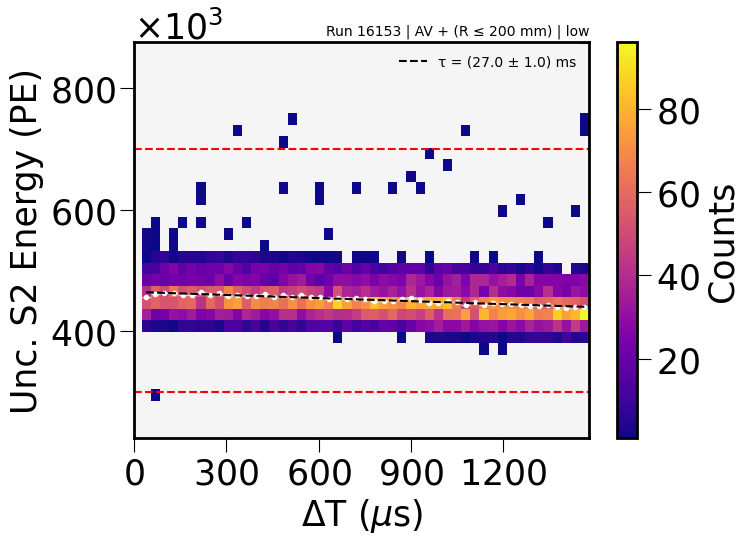

Fit: N0 = (453386.53 ± 785.68) PE, τ = (23.02 ± 1.13) ms
     χ² / ndof = 1.08


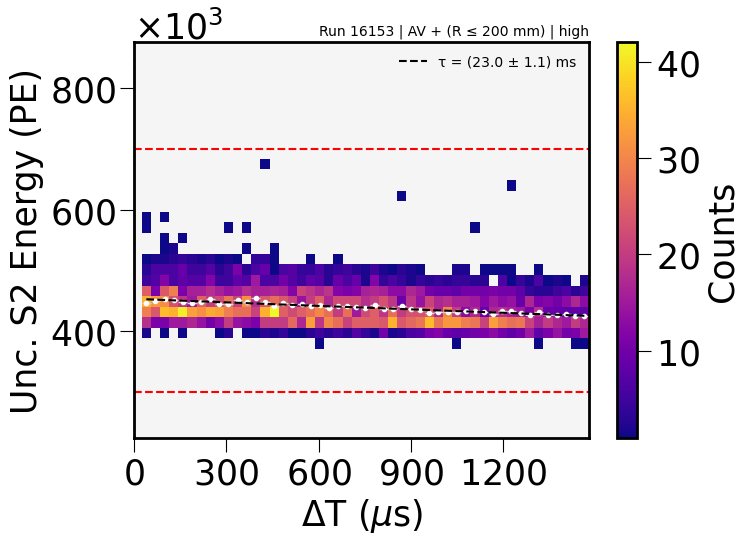

In [30]:
# Global
rad_lim = 200

# Use exponential decay function with b = 0
def exp_bfixed(x, N0, tau):
    return crudo.ff.exponential_decay(x, N0, tau, 0)

for key in SEL_DICT.keys():

    print(f"Run {key}:")
    run_id = int(key.split('_')[0])
    cath_lim = EXTRA_INFO[key]['cath_lim']

    for width_type in ['low', 'high']:

        temp_df = SEL_DICT[key][width_type + '_df'] 

        # Variables    
        E2 = temp_df['S2e']
        DT = temp_df['DT']
        R  = temp_df['R']

        # Masking
        mask = (DT >= 0) & (DT < cath_lim) & (R <= rad_lim)
        E2_mask  = E2[mask]
        DT_mask  = DT[mask]

        # 2D histogram: normalized by corrected DAQ data taking time
        S2e_DT_map, ex, ey = crudo.pt.hist_2D(DT_mask, E2_mask, x_bins=50, y_bins=50)                           
        S2e_DT_map         = np.ma.masked_where(S2e_DT_map==0, S2e_DT_map)
        
        # ---- Exponential Fit ----- #
        # Preliminary
        DT_down = 0;    DT_up = DT_mask.max()
        if   run_id == 14739:  E2_down = 775e3;  E2_up = 850e3;  DT_down = 300
        elif run_id == 16057:  E2_down = 15e3;  E2_up = 30e3
        elif run_id == 16105:  E2_down = 500e3;  E2_up = 800e3
        elif run_id == 16114:  E2_down = 600e3;  E2_up = 1100e3  
        elif run_id == 16116:  E2_down = 700e3;  E2_up = 1100e3
        elif run_id == 16123:  E2_down = 300e3;  E2_up = 700e3
        elif run_id == 16153:  E2_down = 300e3;  E2_up = 700e3
        else:
            E2_down = 800e3;    E2_up = 1200e3
        

        # Filter the data for the fit
        fit_region_mask = (DT_mask >= DT_down) & (DT_mask <= DT_up) & \
                        (E2_mask >= E2_down) & (E2_mask <= E2_up)
        DT_fit = DT_mask[fit_region_mask]
        E2_fit = E2_mask[fit_region_mask]

        # Compute representative values for the fit
        DT_centers, DT_errors, S2e_means, S2e_errors = crudo.ff.prefit_2D(DT_fit, E2_fit, bins=ex)
        # Filter out points with zero error (bins with 1 event)
        valid_points = S2e_errors > 0
        DT_centers = DT_centers[valid_points];      DT_errors  = DT_errors[valid_points]
        S2e_means  = S2e_means[valid_points];       S2e_errors = S2e_errors[valid_points]

        # Definte the cost function + initial guess
        least_squares = LeastSquares(DT_centers, S2e_means, S2e_errors, exp_bfixed)
        init_guess = [S2e_means.max(), (DT_centers.max() - DT_centers.min()) / 2]
        # print(f'\nInitial guess: N0 = {init_guess[0]:.4f} PE, tau = {init_guess[1]:.4f} μs')

        # Define the Minuit object
        m = Minuit(least_squares, *init_guess)

        # Minimization process of the cost function and error estimation
        m.migrad()
        m.hesse()

        # Results
        popt = m.values;  perr = m.errors
        print(f'Fit: N0 = ({popt[0]:.2f} ± {perr[0]:.2f}) PE, τ = ({popt[1] / 1e3:.2f} ± {perr[1] / 1e3:.2f}) ms')
        FIT_PARAMETERS[key][width_type]["S2e"] = {"N0_CV": popt[0], "N0_err": perr[0], "tau_CV": popt[1], "tau_err": perr[1]}
        
        # Reduced chi-square
        chi2 = m.fval
        ndof = len(DT_centers) - m.nfit
        print(f"     χ² / ndof = {chi2 / ndof:.2f}")

        # ----- Plotting ----- #
        plt.figure(figsize=(8, 6))
        # Data
        plt.pcolormesh(ex, ey, S2e_DT_map.T, cmap='plasma', shading='auto')
        cbar = plt.colorbar(label='Counts', shrink=1.0)
        # cbar.formatter.set_powerlimits((-3, -3))

        # Fit
        fit_y = exp_bfixed(DT_centers, *popt)
        plt.errorbar(DT_centers, S2e_means, xerr=DT_errors, yerr=S2e_errors, fmt='o', c='white', ecolor='lightgray', lw=1.0, markersize=3)
        plt.plot(DT_centers, fit_y, c='black', ls='--', lw=1.5, zorder=3, label=f'τ = ({popt[1] / 1e3:.1f} ± {perr[1] / 1e3:.1f}) ms')
        plt.axvline(x=DT_down, c='red', ls='--')
        plt.axhline(y=E2_down, c='red', ls='--', lw=1.5)
        plt.axhline(y=E2_up, c='red', ls='--', lw=1.5)

        # ----- Styling ----- #
        plt.xlabel('$\Delta$T ($\mu$s)')
        plt.ylabel('Unc. S2 Energy (PE)')
        plt.xlim(0, ex[-1])
        plt.ylim(0.75*E2_down, 1.25*E2_up)    
        plt.xticks(np.arange(0, DT_mask.max(), 300))
        plt.ticklabel_format(axis='y', style='sci', scilimits=(3, 3))
        plt.title(f'Run {key} | AV + (R ≤ {rad_lim} mm) | {width_type}', fontsize=10, loc='right')
        plt.legend(loc='upper right', facecolor='whitesmoke', fontsize=10)

        plt.gca().set_facecolor("whitesmoke")
        plt.tight_layout()
        # plt.savefig(f'/lhome/ific/c/ccortesp/Analysis/NEXT-100/Cmmssnng/images/LT_run_{key}.pdf')
        plt.show() 

## Apply Corrections

In [72]:
FIT_PARAMETERS

{'16123': {'S1e': {'m_CV': 0.6909435524465888,
   'm_err': 0.0029068088890605768,
   'b_CV': 1023.8384648336196,
   'b_err': 2.3709836555182022},
  'S2e': {'N0_CV': 494968.92226288194,
   'N0_err': 491.8835332180141,
   'tau_CV': 32115.047594557534,
   'tau_err': 1216.3977606173528}}}

In [31]:
for key in SEL_DICT.keys():

    print(f"--- Run {key} ---")
    cath_lim = EXTRA_INFO[key]['cath_lim']

    for width_type in ['low', 'high']:

        temp_df = SEL_DICT[key][width_type + '_df'] 

        # Fit parameters
        CV_fit = [FIT_PARAMETERS[key][width_type]['S1e']['m_CV'],  FIT_PARAMETERS[key][width_type]['S1e']['b_CV']]
        LT_fit = [FIT_PARAMETERS[key][width_type]['S2e']['N0_CV'], FIT_PARAMETERS[key][width_type]['S2e']['tau_CV']]
            
        # Apply corrections
        temp_df = crudo.ef.correct_S1e   (temp_df, CV_fit, cath_lim, output_column='S1e_corr')      # S1 energy
        temp_df = crudo.ef.correct_S2e_LT(temp_df, LT_fit,           output_column='S2e_corr_LT')   # S2 energy by lifetime
        temp_df = crudo.ef.correct_S2e_map(temp_df, cath_lim)                                       # S2 energy by radial map
    
    # Apply S2 energy correction by fixed geometric map
    # doro_df = crudo.ef.correct_S2e_map_fixed(doro_df, ref_energy_map, x_edges, y_edges)

--- Run 16153 ---


## Control Plots

#### $S1e$ - Active Volume

Run 16153:


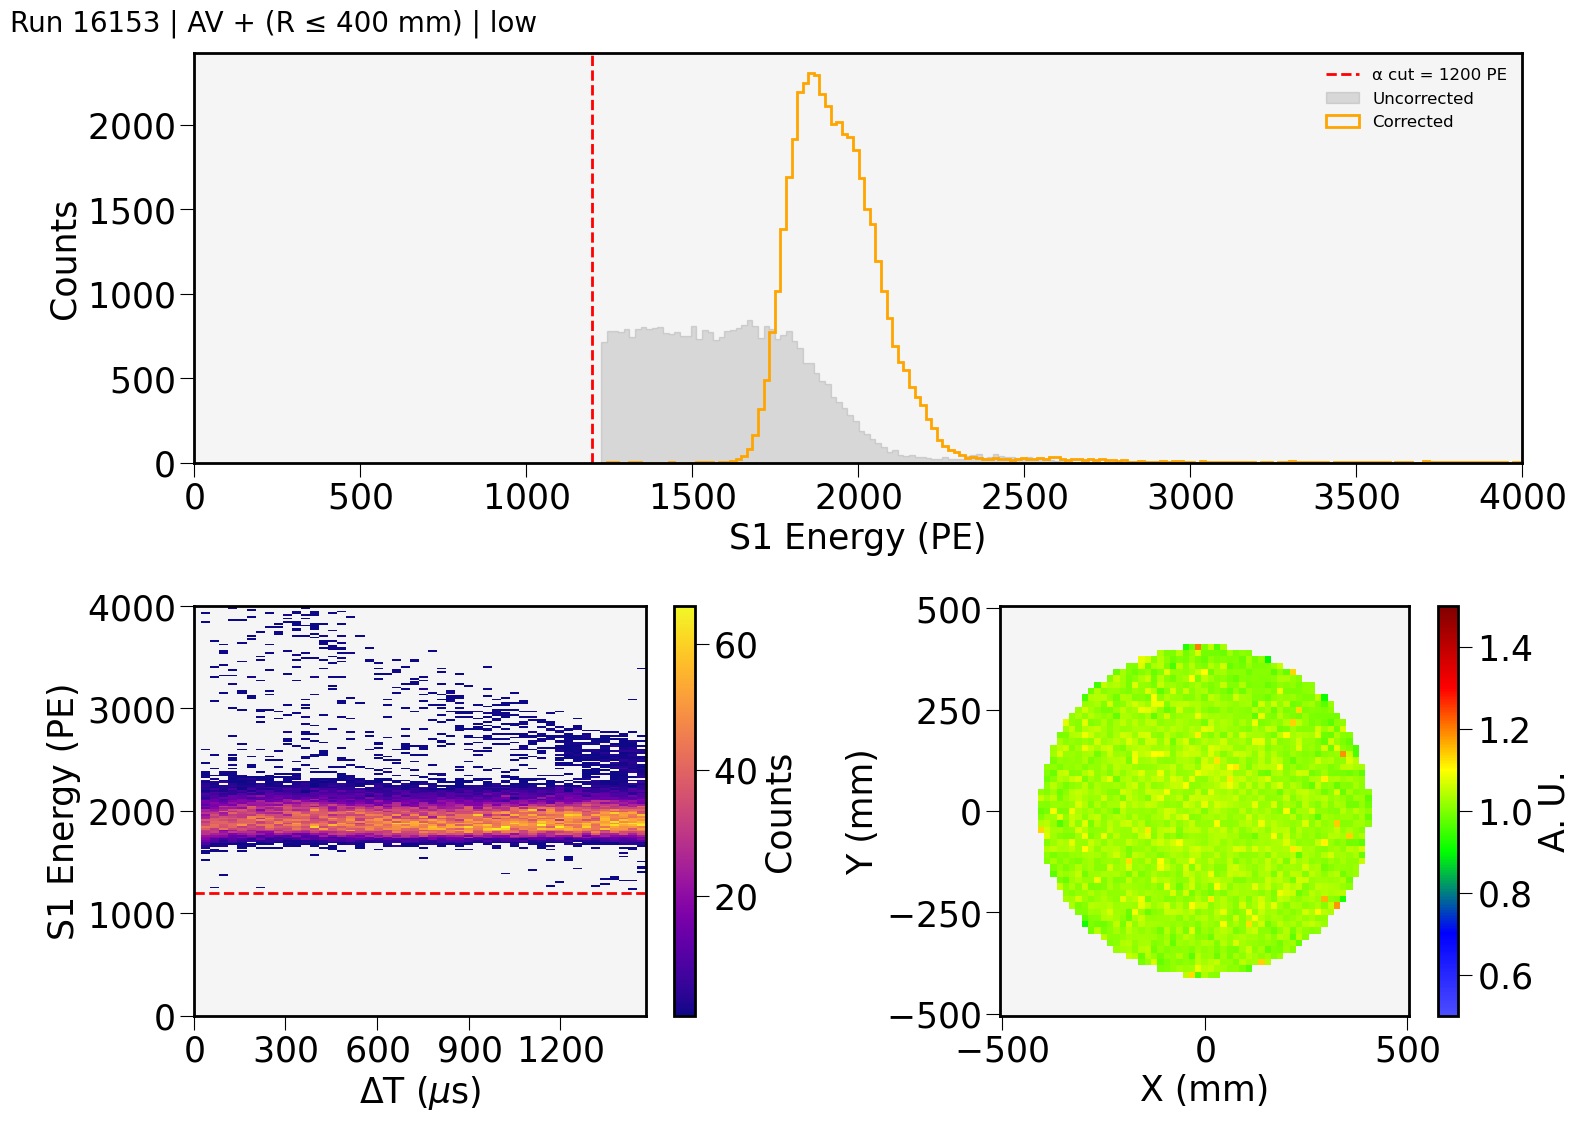

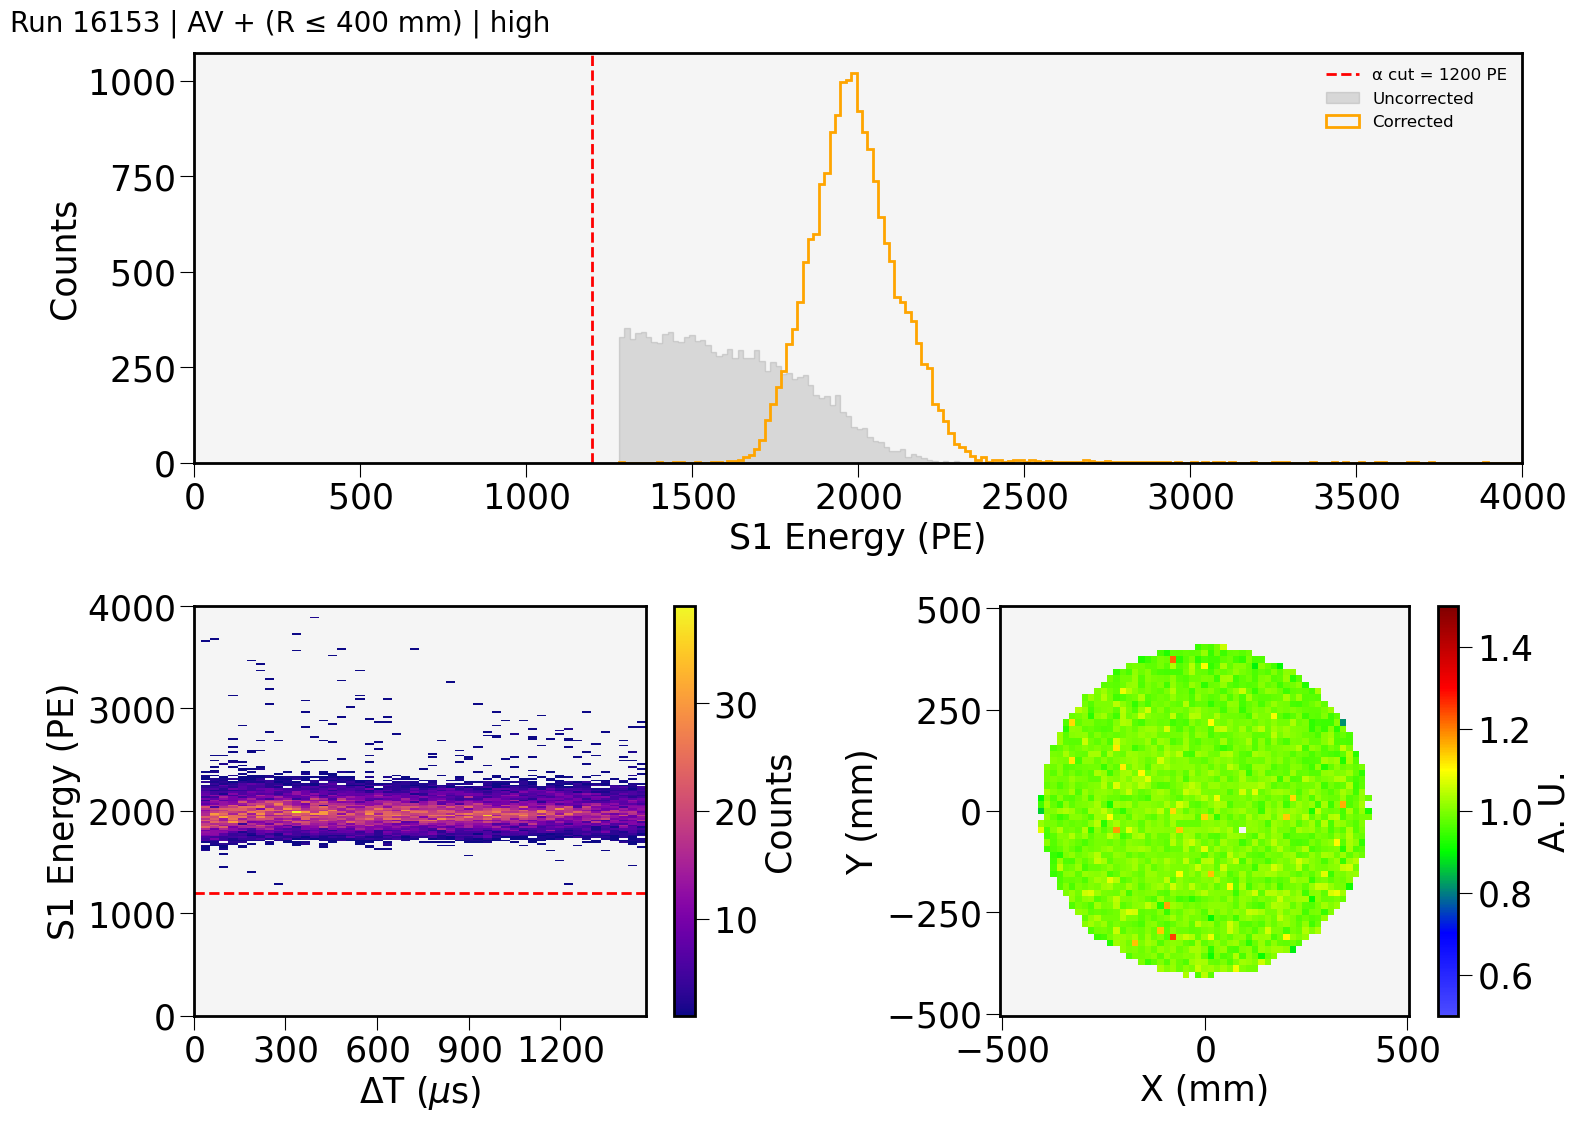

In [33]:
# Global
e1_lim = 4e3
rad_lim = 400

for key in SEL_DICT.keys():

    print(f"Run {key}:")
    for width_type in ['low', 'high']:

        temp_df = SEL_DICT[key][width_type + '_df'] 
    
        # Variables
        X = temp_df['X']
        Y = temp_df['Y']
        R = np.sqrt(X**2 + Y**2)
        DT  = temp_df['DT']
        E1  = temp_df['S1e']
        E1c = temp_df['S1e_corr']

        # Masking
        mask = (DT >= 0) & (DT < cath_lim) & (E1 < e1_lim) & (R <= rad_lim)
        # mask = None
        if mask is not None:
            X  = X[mask];    Y = Y[mask];    DT = DT[mask];
            E1 = E1[mask];   E1c = E1c[mask]

        # 2D histogram: normalized by corrected DAQ data taking time
        S1e_DT_map, ex, ey = crudo.pt.hist_2D(DT, E1c, x_bins=50, y_bins=250)                        
        S1e_DT_map = np.ma.masked_where(S1e_DT_map == 0, S1e_DT_map)

        # Energy map
        s1e_map, ex_map, ey_map = crudo.pt.mapping(X, Y, wei=E1c, bin_scale=1, max_limit=crudo.pt.N100_rad, norm=True)
        s1e_map = np.ma.masked_where(s1e_map==0, s1e_map)

        # ----- Plotting ----- #
        fig = plt.figure(figsize=(16, 12))
        gs = GridSpec(2, 2, figure=fig)

        ax_top = fig.add_subplot(gs[0, :])
        ax_bottom_left = fig.add_subplot(gs[1, 0])
        ax_bottom_right = fig.add_subplot(gs[1, 1])

        # Upper left
        ax_top.hist(E1, bins=ey, histtype='stepfilled', lw=1.0, color='grey', alpha=0.25, ec='grey', label='Uncorrected')
        ax_top.hist(E1c, bins=ey, histtype='step', lw=2.0, color='orange', alpha=1.0, ec='orange', label='Corrected')
        ax_top.set_xlabel('S1 Energy (PE)')
        ax_top.set_ylabel('Counts')
        ax_top.set_xlim(0, e1_lim)
        # ax_top.set_yscale('log')
        ax_top.axvline(x=ALPHA_CUT, c='red', ls='--', lw=2.0, label=f'α cut = {ALPHA_CUT} PE')
        ax_top.legend(loc='upper right', fontsize=12, facecolor='none')
        ax_top.set_facecolor('whitesmoke')

        # Lower left
        pcm = ax_bottom_left.pcolormesh(ex, ey, S1e_DT_map.T, cmap='plasma', shading='auto')
        cbar = fig.colorbar(pcm, ax=ax_bottom_left, label='Counts')
        ax_bottom_left.set_xlabel('$\Delta$T ($\mu$s)')
        ax_bottom_left.set_ylabel('S1 Energy (PE)')
        ax_bottom_left.set_xlim(ex[0], ex[-1])
        ax_bottom_left.set_ylim(0, e1_lim)
        ax_bottom_left.set_xticks(np.arange(0, DT.max(), 300))
        ax_bottom_left.axhline(y=ALPHA_CUT, c='red', ls='--', lw=2.0)
        ax_bottom_left.set_facecolor('whitesmoke')

        # Lower right
        pcm = ax_bottom_right.pcolormesh(ex_map, ey_map, s1e_map.T, cmap=crudo.pt.custom_hsv, shading='auto', vmin=0.5, vmax=1.5)
        cbar = fig.colorbar(pcm, ax=ax_bottom_right, label='A. U.')
        ax_bottom_right.set_xlabel('X (mm)')
        ax_bottom_right.set_ylabel('Y (mm)')
        ax_bottom_right.set_aspect('equal', adjustable='box')
        ax_bottom_right.set_facecolor('whitesmoke')


        # Single title for the figure
        fig.suptitle(f'Run {key} | AV + (R ≤ {rad_lim} mm) | {width_type}', fontsize=20, x=0, y=0.95, ha='left')

        plt.tight_layout()
        plt.show()

#### $S1e$ - Cathode

Run 16153:


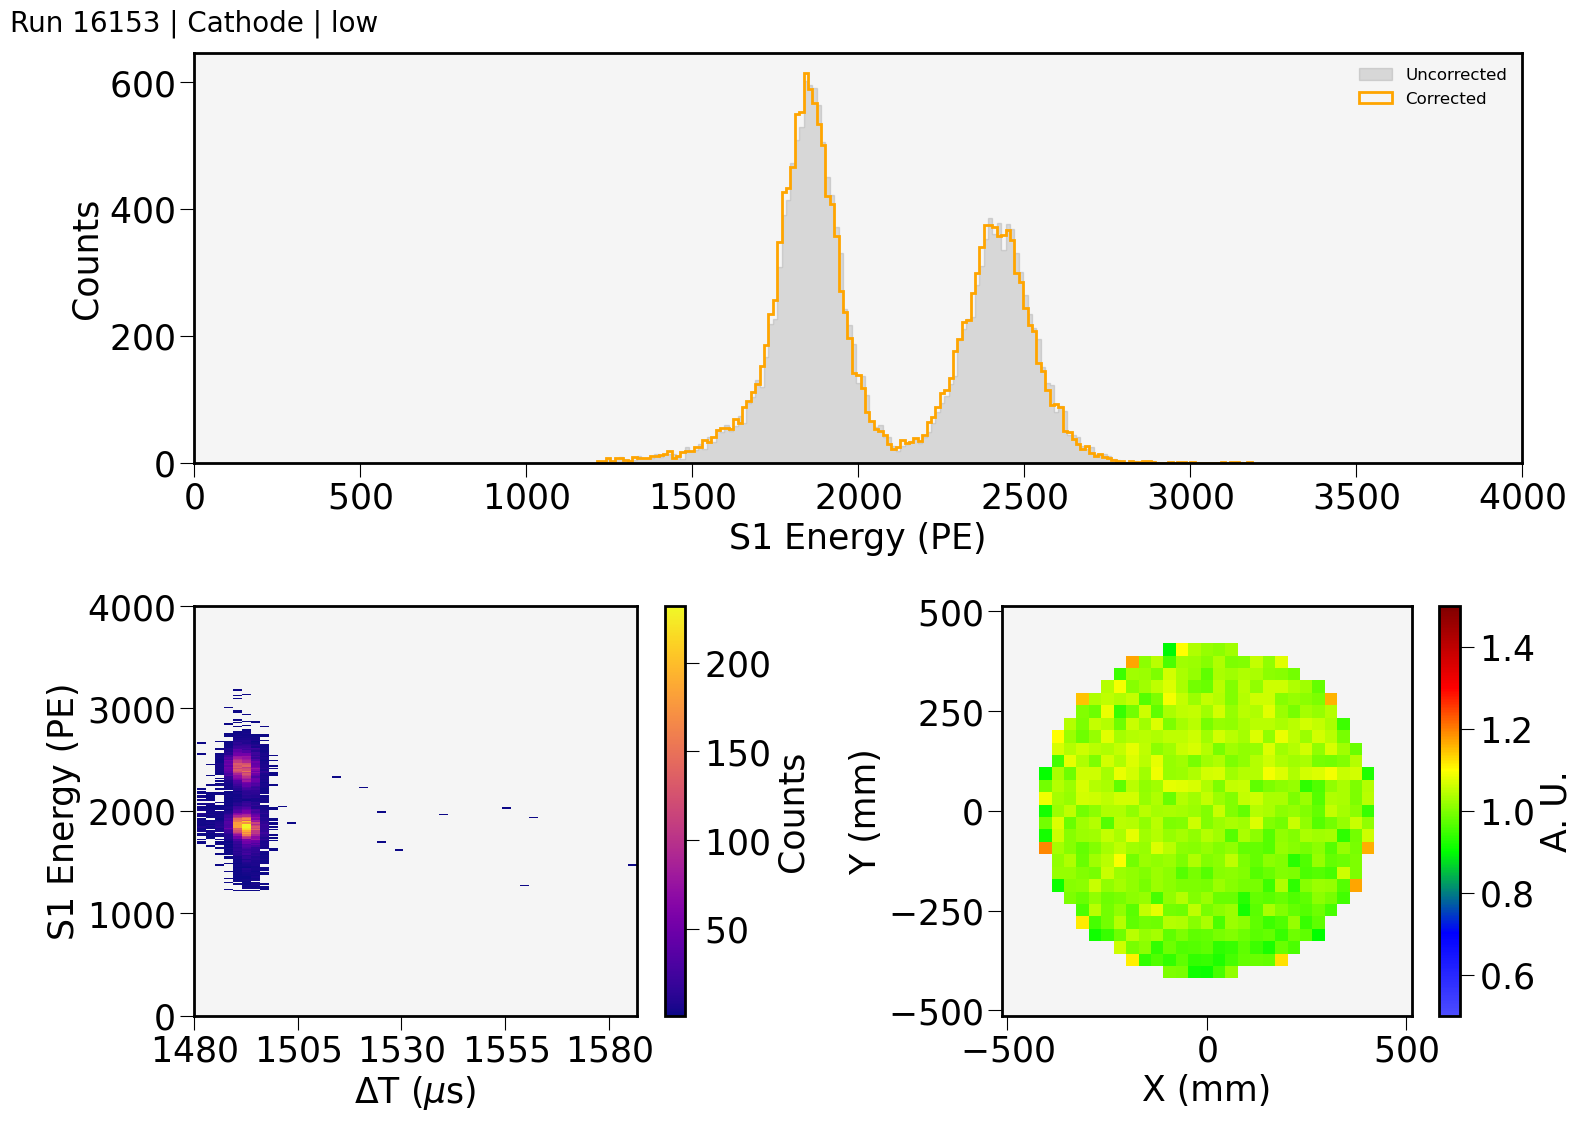

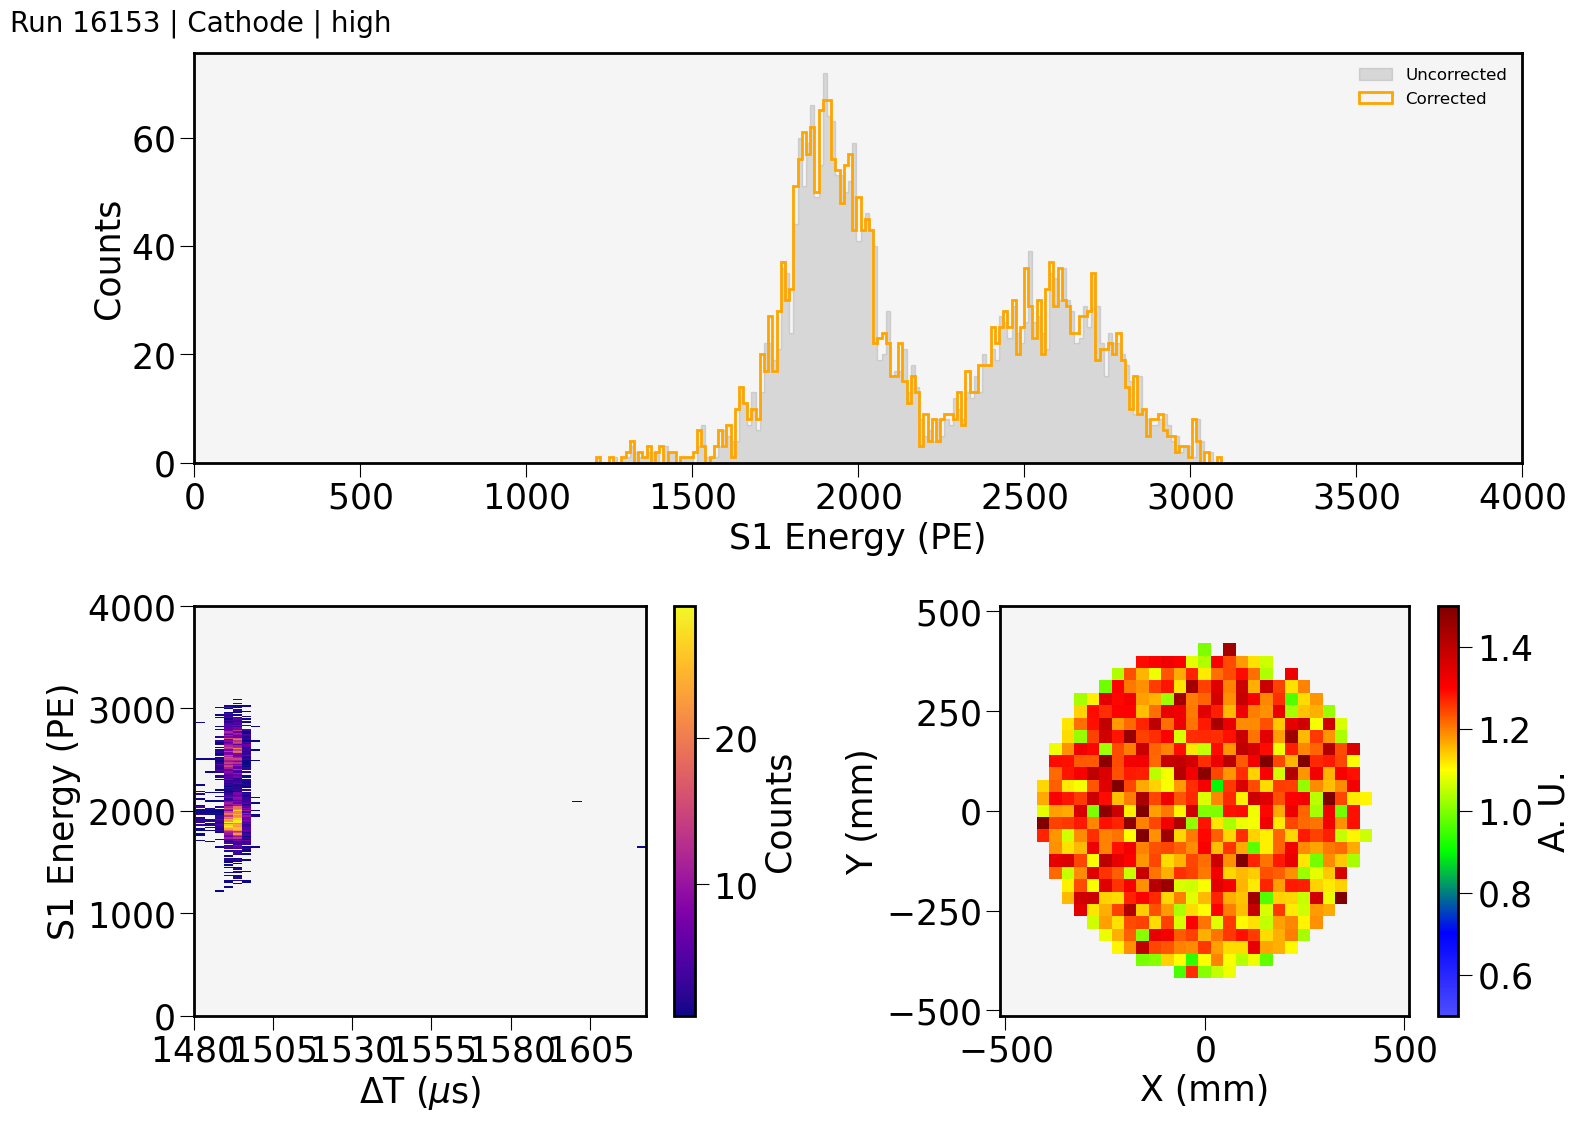

In [34]:
# Global
e1_lim = 4e3

for key in SEL_DICT.keys():

    print(f"Run {key}:")
    for width_type in ['low', 'high']:

        temp_df = SEL_DICT[key][width_type + '_df'] 
    
        # Variables
        X = temp_df['X']
        Y = temp_df['Y']
        R = np.sqrt(X**2 + Y**2)
        DT  = temp_df['DT']
        E1  = temp_df['S1e']
        E1c = temp_df['S1e_corr']

        # Masking
        mask = (DT >= cath_lim) & (E1 < e1_lim) & (R <= rad_lim)
        # mask = None
        if mask is not None:
            X  = X[mask];    Y = Y[mask];    DT = DT[mask];
            E1 = E1[mask];   E1c = E1c[mask]

        # 2D histogram: normalized by corrected DAQ data taking time
        S1e_DT_map, ex, ey = crudo.pt.hist_2D(DT, E1c, x_bins=50, y_bins=150)                        
        S1e_DT_map = np.ma.masked_where(S1e_DT_map == 0, S1e_DT_map)

        # Energy map
        s1e_map, ex_map, ey_map = crudo.pt.mapping(X, Y, wei=E1c, bin_scale=2, max_limit=crudo.pt.N100_rad, norm=True)
        s1e_map = np.ma.masked_where(s1e_map==0, s1e_map)

        # ----- Plotting ----- #
        fig = plt.figure(figsize=(16, 12))
        gs = GridSpec(2, 2, figure=fig)

        ax_top = fig.add_subplot(gs[0, :])
        ax_bottom_left = fig.add_subplot(gs[1, 0])
        ax_bottom_right = fig.add_subplot(gs[1, 1])

        # Upper left
        ax_top.hist(E1, bins=ey, histtype='stepfilled', lw=1.0, color='grey', alpha=0.25, ec='grey', label='Uncorrected')
        ax_top.hist(E1c, bins=ey, histtype='step', lw=2.0, color='orange', alpha=1.0, ec='orange', label='Corrected')
        ax_top.set_xlabel('S1 Energy (PE)')
        ax_top.set_ylabel('Counts')
        ax_top.set_xlim(0, e1_lim)
        # ax_top.set_yscale('log')
        # ax_top.axvline(x=ALPHA_CUT, c='red', ls='--', lw=2.0, label=f'α cut = {ALPHA_CUT} PE')
        ax_top.legend(loc='upper right', fontsize=12, facecolor='none')
        ax_top.set_facecolor('whitesmoke')

        # Lower left
        pcm = ax_bottom_left.pcolormesh(ex, ey, S1e_DT_map.T, cmap='plasma', shading='auto')
        cbar = fig.colorbar(pcm, ax=ax_bottom_left, label='Counts')
        ax_bottom_left.set_xlabel('$\Delta$T ($\mu$s)')
        ax_bottom_left.set_ylabel('S1 Energy (PE)')
        ax_bottom_left.set_xlim(ex[0], ex[-1])
        ax_bottom_left.set_ylim(0, e1_lim)
        ax_bottom_left.set_xticks(np.arange(int(ex[0]), int(ex[-1]), 25))
        # ax_bottom_left.axhline(y=ALPHA_CUT, c='red', ls='--', lw=2.0)
        ax_bottom_left.set_facecolor('whitesmoke')

        # Lower right
        pcm = ax_bottom_right.pcolormesh(ex_map, ey_map, s1e_map.T, cmap=crudo.pt.custom_hsv, shading='auto', vmin=0.5, vmax=1.5)
        cbar = fig.colorbar(pcm, ax=ax_bottom_right, label='A. U.')
        ax_bottom_right.set_xlabel('X (mm)')
        ax_bottom_right.set_ylabel('Y (mm)')
        ax_bottom_right.set_aspect('equal', adjustable='box')
        ax_bottom_right.set_facecolor('whitesmoke')


        # Single title for the figure
        fig.suptitle(f'Run {key} | Cathode | {width_type}', fontsize=20, x=0, y=0.95, ha='left')

        plt.tight_layout()
        plt.show()

#### $S2e$ - Active Volume

Run 16153:


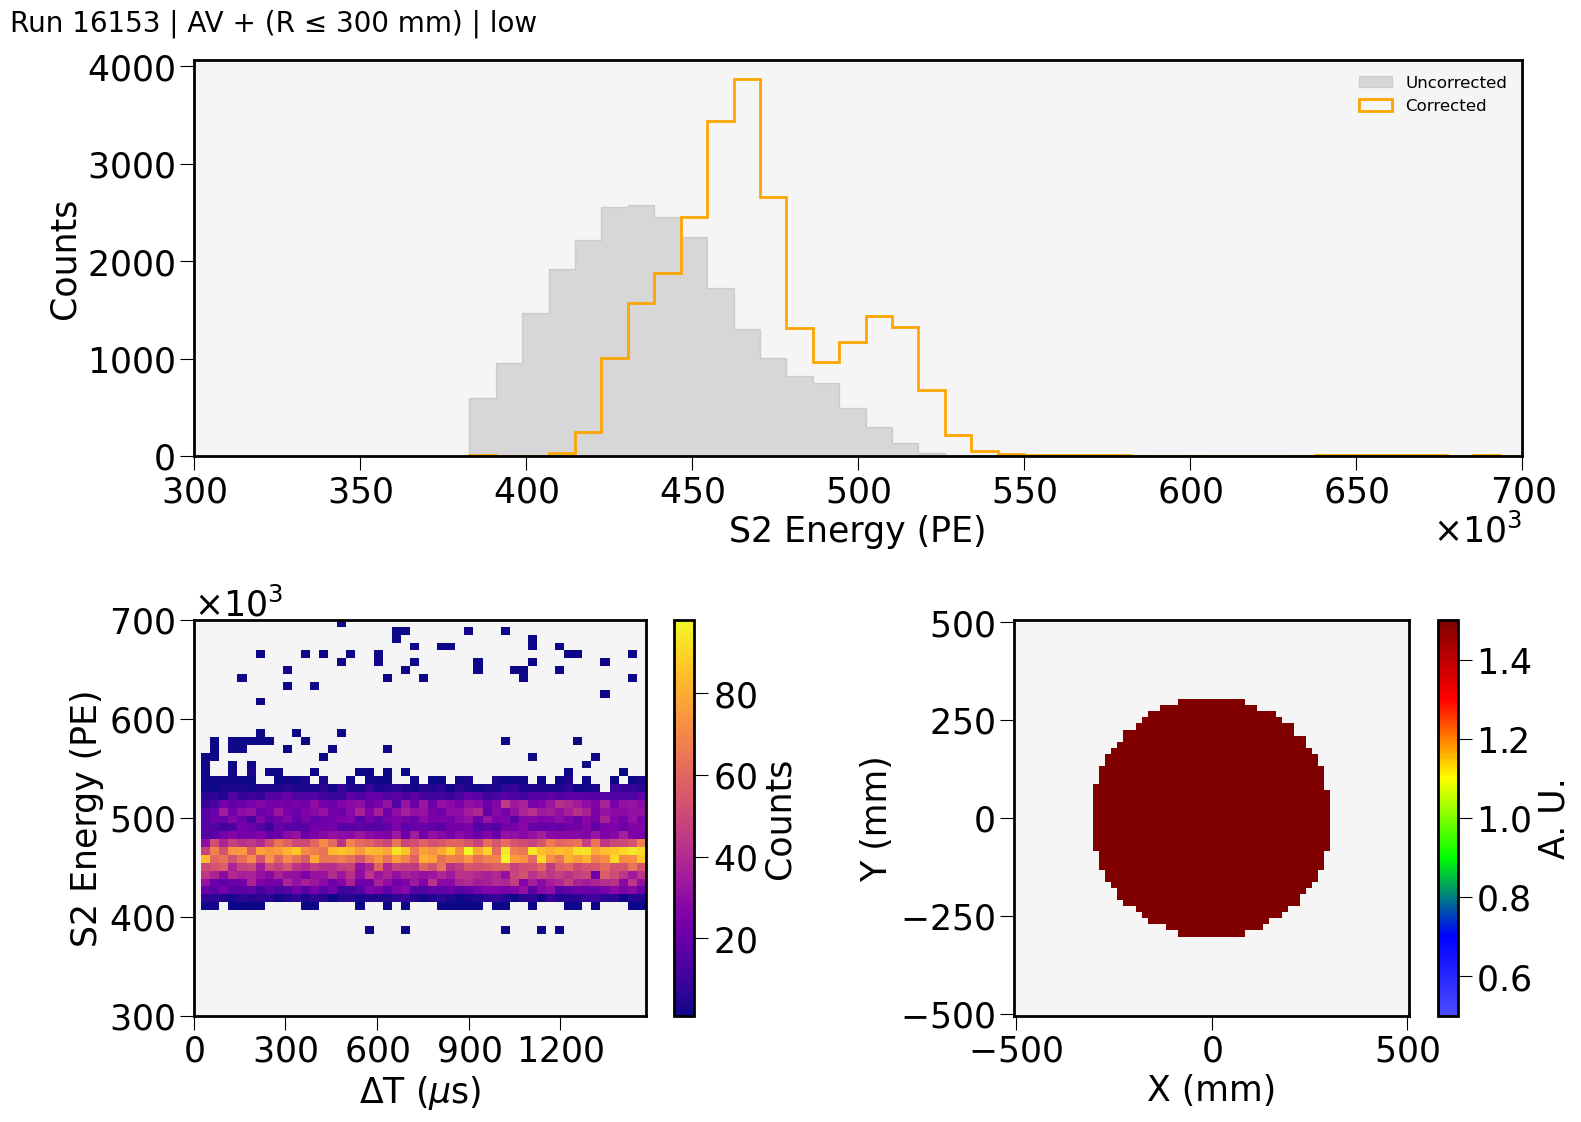

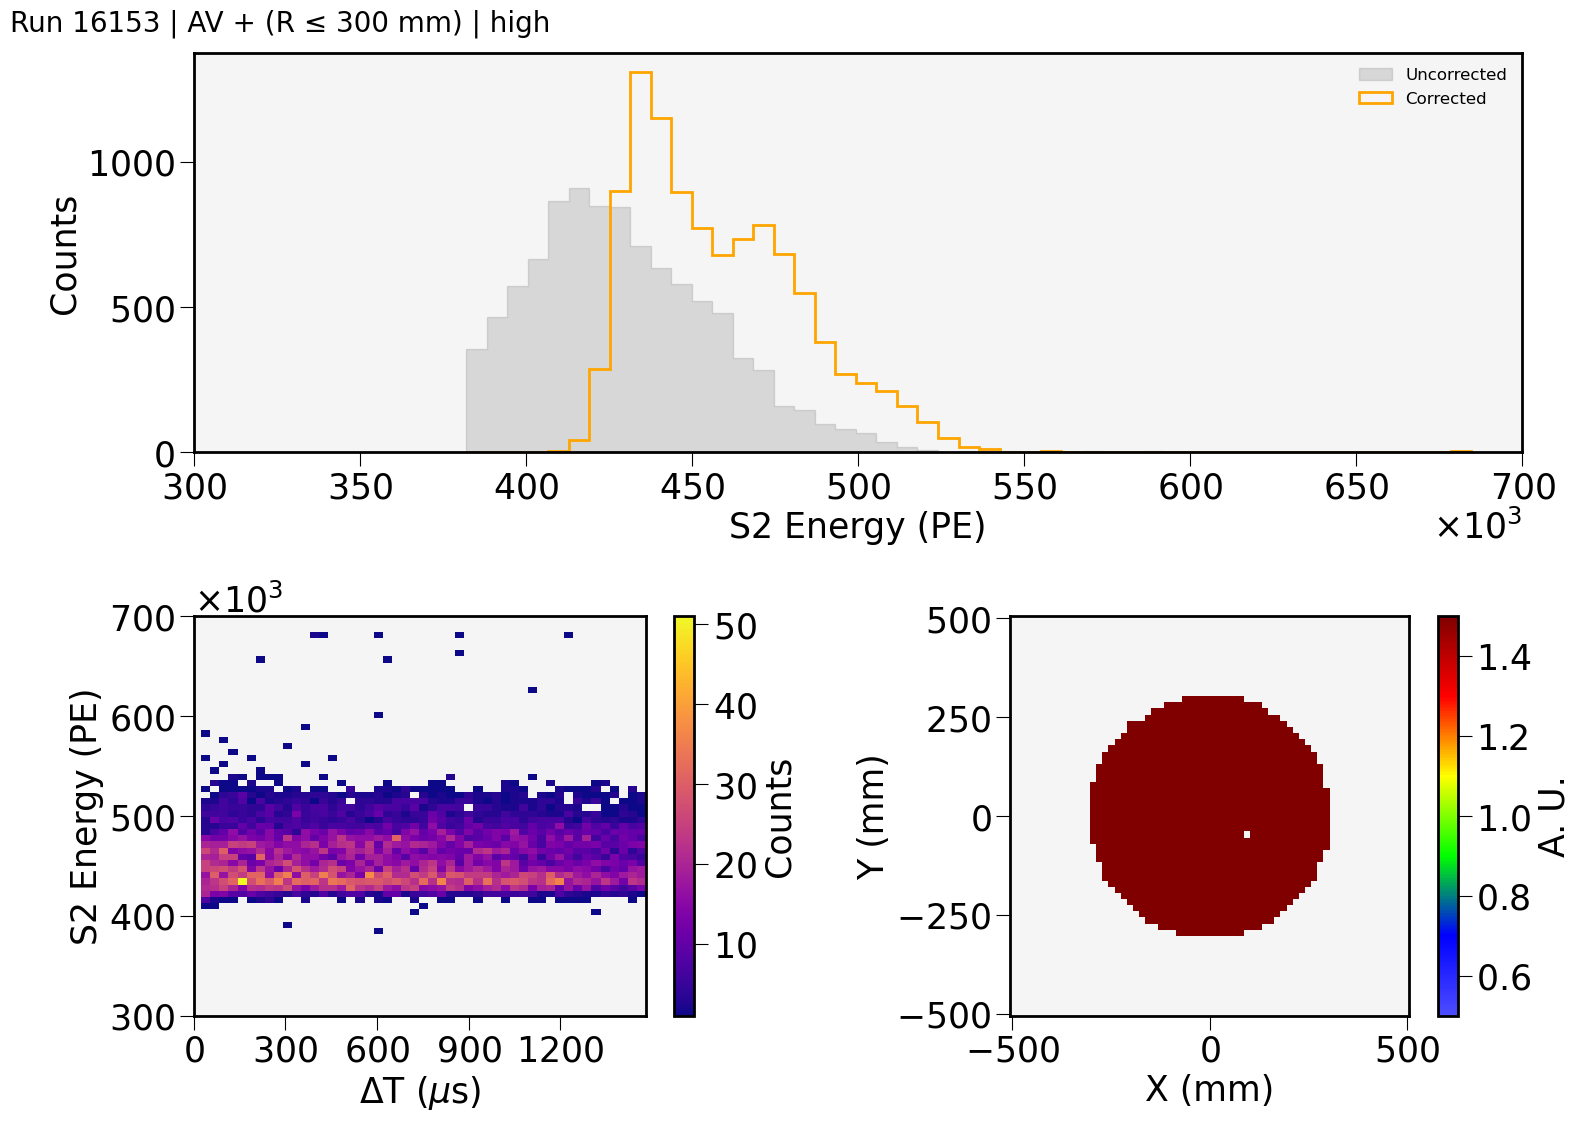

In [35]:
# Global
r_lims = [300]
# r_lims = [100, 200, 300, 400, 500]

for key in SEL_DICT.keys():

    print(f"Run {key}:")
    run_id = int(key.split('_')[0])

    if run_id == 14739: E2_min = 600e3;  E2_max = 1100e3
    elif run_id == 16057: E2_min = 15e3;   E2_max = 30e3
    elif run_id == 16123: E2_min = 300e3;  E2_max = 700e3
    elif run_id == 16153: E2_min = 300e3;  E2_max = 700e3

    for width_type in ['low', 'high']:

        temp_df = SEL_DICT[key][width_type + '_df']

        for rad_lim in r_lims:
    
            # Variables
            X = temp_df['X']
            Y = temp_df['Y']
            R = np.sqrt(X**2 + Y**2)
            DT  = temp_df['DT']
            E2  = temp_df['S2e']
            E2c = temp_df['S2e_corr']

            # Masking
            mask = (DT >= 0) & (DT < cath_lim)& (R <= rad_lim) & (E2 >= E2_min) & (E2 <= E2_max)
            # mask = None
            if mask is not None:
                X  = X[mask];    Y = Y[mask];   R = R[mask];   
                DT = DT[mask];   E2 = E2[mask];   E2c = E2c[mask]

            # 2D histogram: normalized by corrected DAQ data taking time
            S2e_DT_map, ex, ey = crudo.pt.hist_2D(DT, E2c, x_bins=50, y_bins=50)                        
            S2e_DT_map = np.ma.masked_where(S2e_DT_map == 0, S2e_DT_map)

            # Energy map
            s2e_map, ex_map, ey_map = crudo.pt.mapping(X, Y, wei=E2c, bin_scale=1, max_limit=crudo.pt.N100_rad, norm=False)
            s2e_map = np.ma.masked_where(s2e_map==0, s2e_map)

            # ----- Plotting ----- #
            fig = plt.figure(figsize=(16, 12))
            gs = GridSpec(2, 2, figure=fig)

            ax_top = fig.add_subplot(gs[0, :])
            ax_bottom_left = fig.add_subplot(gs[1, 0])
            ax_bottom_right = fig.add_subplot(gs[1, 1])

            # Upper left
            ax_top.hist(E2, bins=ey, histtype='stepfilled', lw=1.0, color='grey', alpha=0.25, ec='grey', label='Uncorrected')
            ax_top.hist(E2c, bins=ey, histtype='step', lw=2.0, color='orange', alpha=1.0, ec='orange', label='Corrected')
            ax_top.set_xlabel('S2 Energy (PE)')
            ax_top.set_ylabel('Counts')
            ax_top.set_xlim(E2_min, E2_max)
            # ax_top.set_yscale('log')
            ax_top.ticklabel_format(axis='x', style='sci', scilimits=(3,3))
            ax_top.legend(loc='upper right', fontsize=12, facecolor='none')
            ax_top.set_facecolor('whitesmoke')

            # Lower left
            pcm = ax_bottom_left.pcolormesh(ex, ey, S2e_DT_map.T, cmap='plasma', shading='auto')
            cbar = fig.colorbar(pcm, ax=ax_bottom_left, label='Counts')
            ax_bottom_left.set_xlabel('$\Delta$T ($\mu$s)')
            ax_bottom_left.set_ylabel('S2 Energy (PE)')
            ax_bottom_left.set_xlim(ex[0], ex[-1])
            ax_bottom_left.set_ylim(E2_min, E2_max)
            ax_bottom_left.set_xticks(np.arange(0, DT.max(), 300))
            ax_bottom_left.ticklabel_format(axis='y', style='sci', scilimits=(3,3))
            ax_bottom_left.set_facecolor('whitesmoke')

            # Lower right
            pcm = ax_bottom_right.pcolormesh(ex_map, ey_map, s2e_map.T, cmap=crudo.pt.custom_hsv, shading='auto', vmin=0.5, vmax=1.5)
            cbar = fig.colorbar(pcm, ax=ax_bottom_right, label='A. U.')
            ax_bottom_right.set_xlabel('X (mm)')
            ax_bottom_right.set_ylabel('Y (mm)')
            ax_bottom_right.set_aspect('equal', adjustable='box')
            ax_bottom_right.set_facecolor('whitesmoke')

            # Single title for the figure
            fig.suptitle(f'Run {key} | AV + (R ≤ {rad_lim} mm) | {width_type}', fontsize=20, x=0, y=0.95, ha='left')

            plt.tight_layout()
            # plt.savefig(f'/lhome/ific/c/ccortesp/Analysis/NEXT-100/Cmmssnng/images/S2e_corr_run_{key}_AV_R{rad_lim}.pdf')
            plt.show()

#### $S2e$ - Cathode

Total events: 13457
[273, 370, 440, 643, 685, 964, 1062, 1105, 1357, 1420, 2596, 2785, 3747, 4007, 4044, 4058, 4070, 4126, 4224, 4279, 4286, 4303, 4357, 4366, 4559, 5162, 5302, 5475, 5503, 5524, 5643, 5748, 6639, 6891, 6912, 7722, 7792, 7848, 7918, 8540, 8617, 8715, 8754, 8768, 8894, 9041, 9319, 9375, 9396, 9410, 10220, 10367, 10627, 10802, 10811, 10816, 10830, 10857, 11076, 11265, 11483, 11602, 11769, 11958, 12191, 12481, 12565, 12607, 12642, 12649, 13130, 13354, 13396, 13473, 13480, 13823, 13990, 14011, 14046, 14186, 14952, 15050, 15155, 16144, 16235, 16795, 16900, 16903, 16924, 16938, 16994, 17022, 18617, 20037, 20081, 20219, 20382, 20503, 20524, 21152, 21155, 21190, 21274, 21320, 21428, 21439, 21504, 21637, 21686, 21714, 21872, 21886, 21984, 22015, 22026, 22075, 22078, 22141, 22180, 22269, 22318, 22388, 22458, 22572, 22591, 22597, 22611, 22639, 22656, 22716, 22779, 22800, 22815, 22864, 22870, 22920, 23104, 23237, 23297, 23332, 23381, 23402, 23458, 24753, 24816, 24837, 24858, 24921,

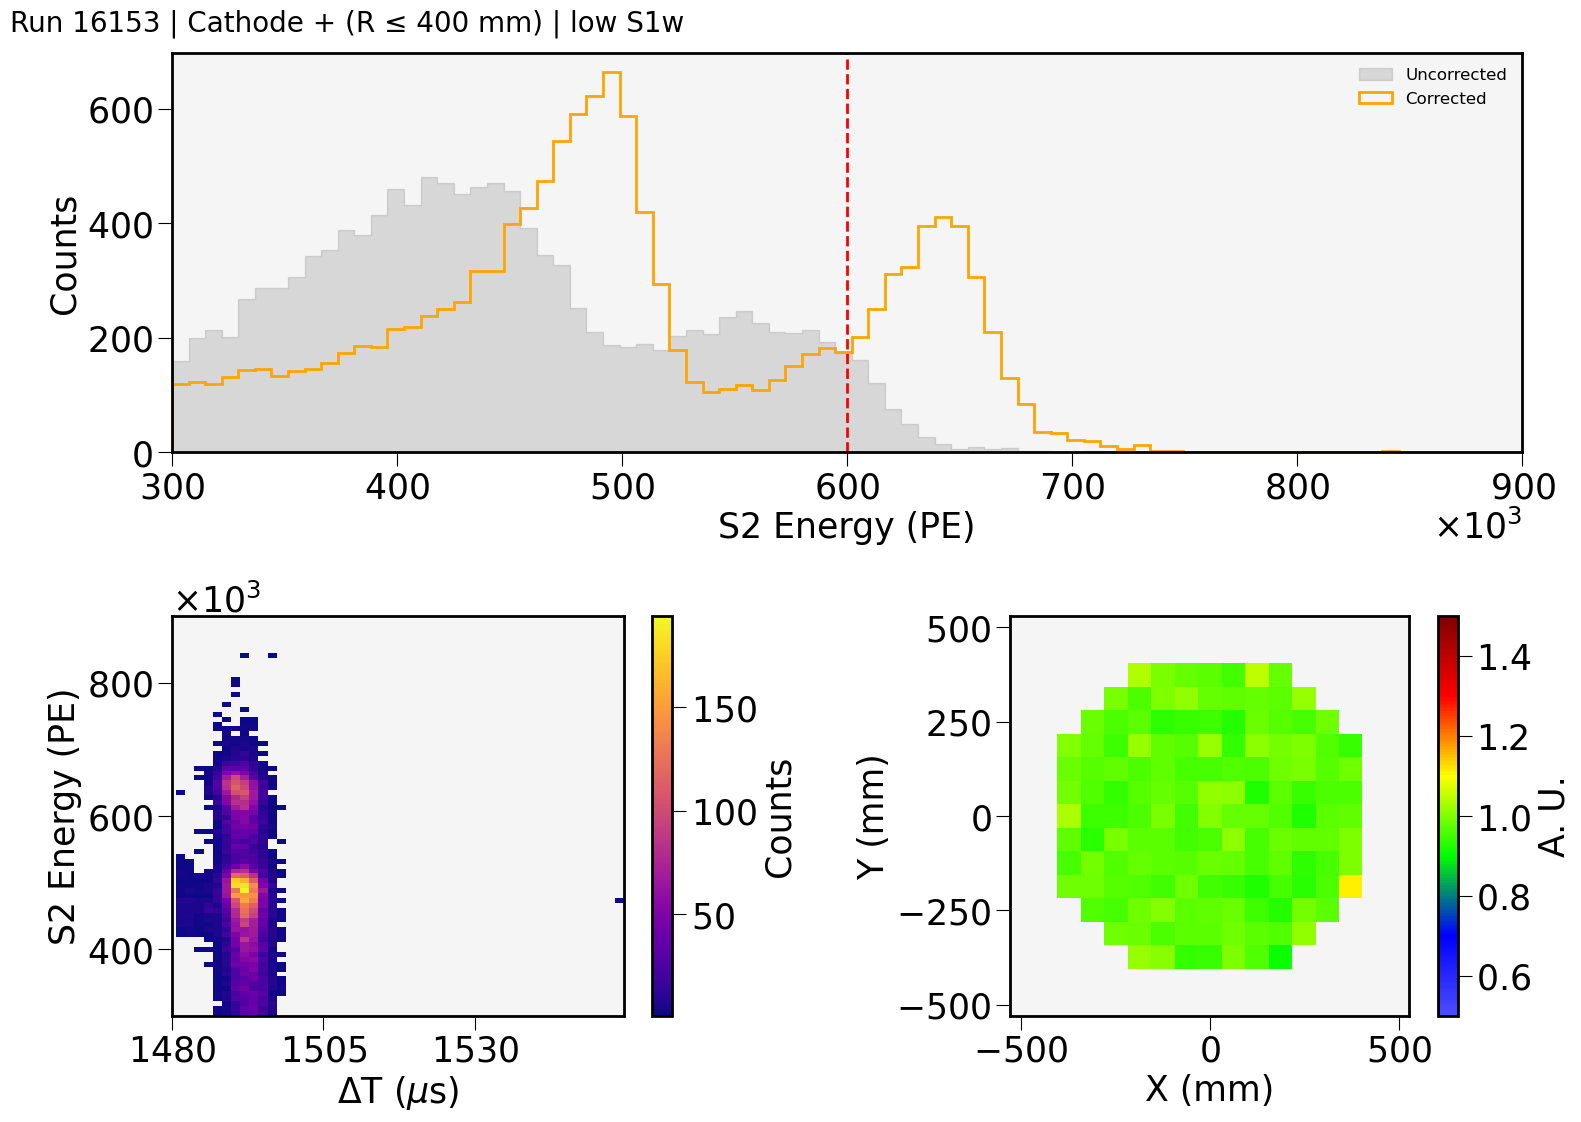

Total events: 1460
[21, 387, 1899, 4111, 4261, 5232, 8547, 10682, 11329, 20209, 20226, 20333, 21218, 21390, 21470, 22845, 23472, 23647, 27252, 29221, 31611, 32076, 34459, 35771, 35869, 36377, 37150, 37204, 37781, 37809, 43892, 48632, 49596, 53083, 54194, 54776, 54819, 57886, 58493, 59802, 60238, 60727, 61647, 62419, 62597, 65134, 66376, 74318, 74376, 76217, 76805, 82368, 82403, 82555, 85291, 88697, 93776, 94057, 94134, 96259, 96385, 96936, 97136, 97150, 97167, 98260, 99733, 100246, 101048, 101118, 103517, 103580, 105445, 109128, 109178, 109192, 109207, 109633, 110378, 110574, 110602, 111100, 112269, 114382, 115275, 115408, 115513, 115534, 115644, 117680, 118747, 122833, 123792, 130757, 132987, 133176, 134011, 134109, 138957, 143513, 143772, 147184, 148566, 148578, 151217, 152291, 152368, 154394, 154499, 161641, 164472, 165120, 167942, 172541, 173321, 173468, 173702, 179065, 181839, 181863, 182259, 183324, 187857, 188834, 189062, 189111, 189209, 191856, 192073, 192903, 193280, 194483, 1

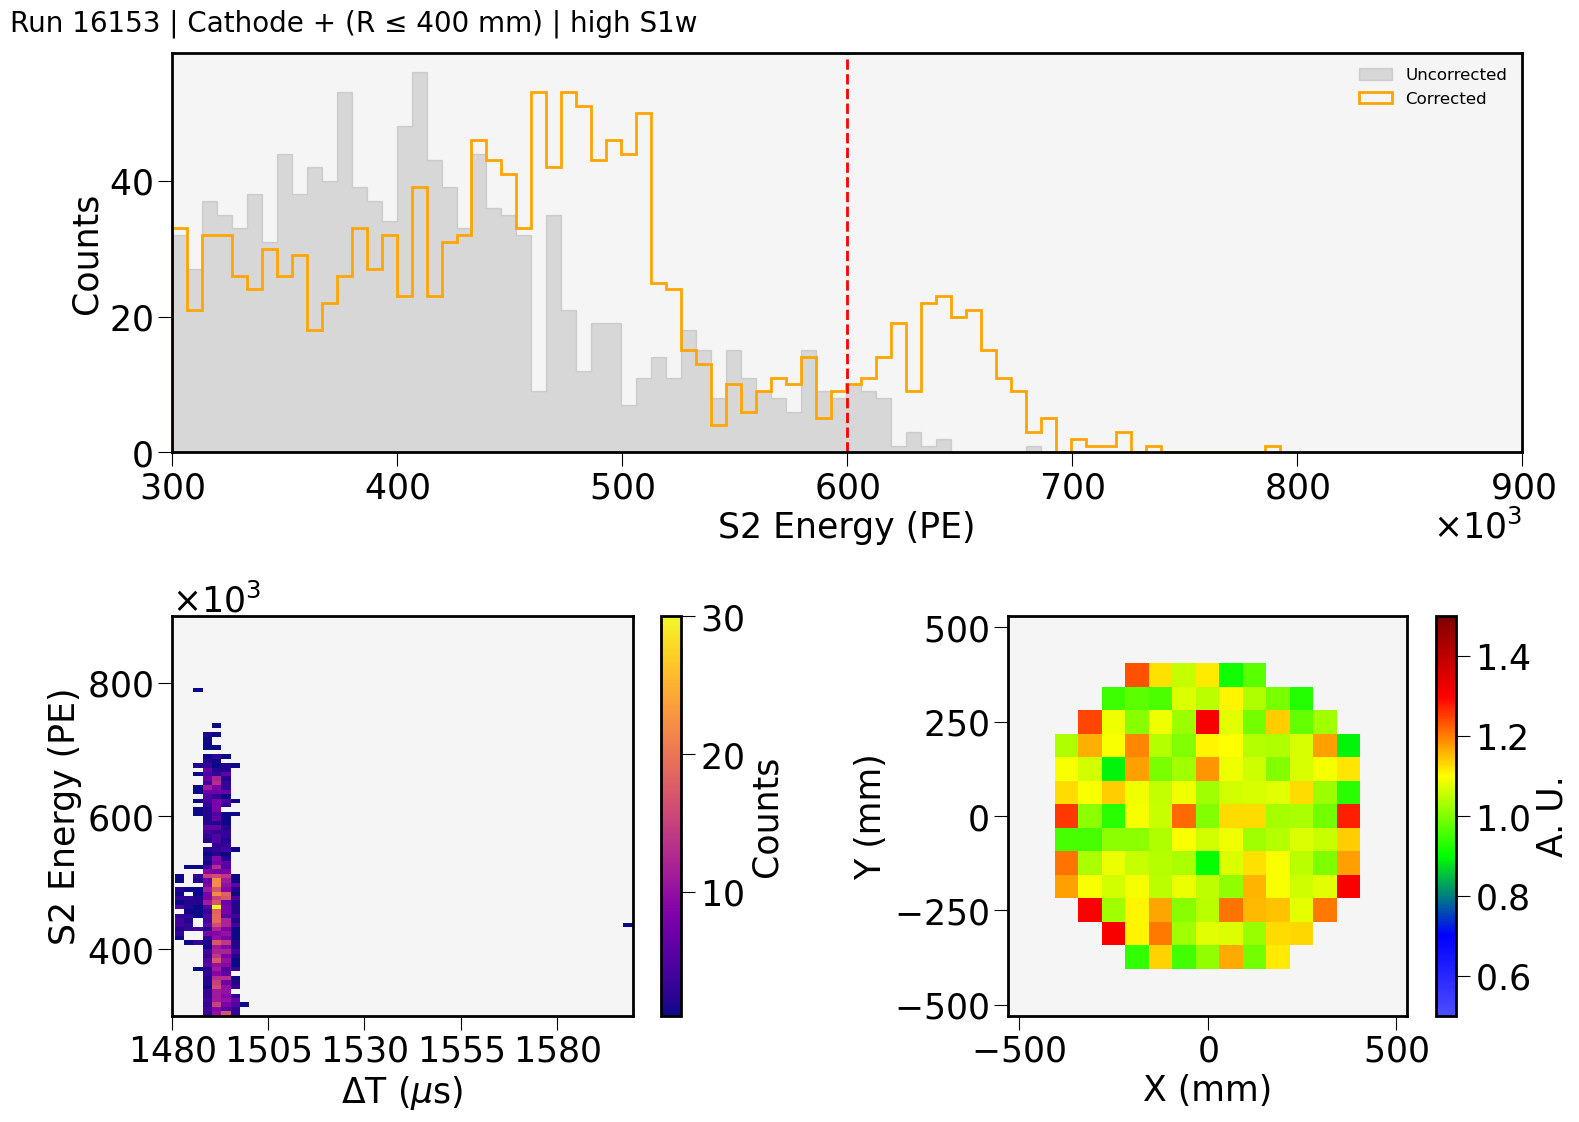

In [52]:
# Global
r_lims = [400]
# r_lims = [100, 200, 300, 400, 500]

limit_218 = 600e3

for key in SEL_DICT.keys():
    
    run_id = int(key.split('_')[0])
    if run_id == 16153: E2_min = 300e3;  E2_max = 900e3

    for width_type in ['low', 'high']:

        temp_df = SEL_DICT[key][width_type + '_df']

        for rad_lim in r_lims:
    
            # Variables
            X = temp_df['X']
            Y = temp_df['Y']
            R = np.sqrt(X**2 + Y**2)
            DT  = temp_df['DT']
            E2  = temp_df['S2e']
            E2c = temp_df['S2e_corr']

            # Masking
            mask = (DT >= cath_lim) & (R <= rad_lim) & (E2c >= E2_min) & (E2c <= E2_max)
            # mask = None
            if mask is not None:
                X  = X[mask];    Y = Y[mask];   R = R[mask];   
                DT = DT[mask];   E2 = E2[mask];   E2c = E2c[mask]

            masked_df = temp_df[mask]
            tot_events  = sorted(masked_df["event"].unique())
            p218_events = sorted(masked_df[masked_df["S2e_corr"] >= limit_218]["event"].unique())
            print(f"Total events: {len(tot_events)}")
            print(tot_events)
            print(f"Run {key} | {width_type.upper()} width | Events with E2c ≥ {limit_218} PE ({len(p218_events)}):")
            print(p218_events)
            print("-" * 50)

            # 2D histogram: normalized by corrected DAQ data taking time
            S2e_DT_map, ex, ey = crudo.pt.hist_2D(DT, E2c, x_bins=50, y_bins=75)                        
            S2e_DT_map = np.ma.masked_where(S2e_DT_map == 0, S2e_DT_map)

            # Energy map
            s2e_map, ex_map, ey_map = crudo.pt.mapping(X, Y, wei=E2c, bin_scale=4, max_limit=crudo.pt.N100_rad, norm=True)
            s2e_map = np.ma.masked_where(s2e_map==0, s2e_map)

            # ----- Plotting ----- #
            fig = plt.figure(figsize=(16, 12))
            gs = GridSpec(2, 2, figure=fig)

            ax_top = fig.add_subplot(gs[0, :])
            ax_bottom_left = fig.add_subplot(gs[1, 0])
            ax_bottom_right = fig.add_subplot(gs[1, 1])

            # Upper left
            ax_top.hist(E2, bins=ey, histtype='stepfilled', lw=1.0, color='grey', alpha=0.25, ec='grey', label='Uncorrected')
            ax_top.hist(E2c, bins=ey, histtype='step', lw=2.0, color='orange', alpha=1.0, ec='orange', label='Corrected')
            ax_top.set_xlabel('S2 Energy (PE)')
            ax_top.set_ylabel('Counts')
            ax_top.set_xlim(E2_min, E2_max)
            # ax_top.set_yscale('log')
            ax_top.ticklabel_format(axis='x', style='sci', scilimits=(3,3))
            ax_top.legend(loc='upper right', fontsize=12, facecolor='none')
            ax_top.axvline(x=limit_218, c='red', ls='--', lw=2.0, label=f'218Po = {limit_218} PE')
            ax_top.set_facecolor('whitesmoke')

            # Lower left
            pcm = ax_bottom_left.pcolormesh(ex, ey, S2e_DT_map.T, cmap='plasma', shading='auto')
            cbar = fig.colorbar(pcm, ax=ax_bottom_left, label='Counts')
            ax_bottom_left.set_xlabel('$\Delta$T ($\mu$s)')
            ax_bottom_left.set_ylabel('S2 Energy (PE)')
            ax_bottom_left.set_xlim(ex[0], ex[-1])
            ax_bottom_left.set_ylim(E2_min, E2_max)
            ax_bottom_left.set_xticks(np.arange(int(ex[0]), int(ex[-1]), 25))
            ax_bottom_left.ticklabel_format(axis='y', style='sci', scilimits=(3,3))
            ax_bottom_left.set_facecolor('whitesmoke')

            # Lower right
            pcm = ax_bottom_right.pcolormesh(ex_map, ey_map, s2e_map.T, cmap=crudo.pt.custom_hsv, shading='auto', vmin=0.5, vmax=1.5)
            cbar = fig.colorbar(pcm, ax=ax_bottom_right, label='A. U.')
            ax_bottom_right.set_xlabel('X (mm)')
            ax_bottom_right.set_ylabel('Y (mm)')
            ax_bottom_right.set_aspect('equal', adjustable='box')
            ax_bottom_right.set_facecolor('whitesmoke')

            # Single title for the figure
            fig.suptitle(f'Run {key} | Cathode + (R ≤ {rad_lim} mm) | {width_type} S1w', fontsize=20, x=0, y=0.95, ha='left')

            plt.tight_layout()
            plt.show()

In [51]:
test_df = SEL_DICT['16153']['doro_df'].copy()
test_df

,event,time,s1_peak,s2_peak,nS1,nS2,S1w,S1h,S1e,S1t,...,DT,Z,Zrms,X,Y,R,Phi,Xrms,Yrms,S1e_corr
2,1626010,1.792130e+09,0,0,1,1,350.0,316.982727,1980.164917,125850.0,...,1490.134399,1490.134399,7.937725,-284.494095,224.662054,362.505074,2.473170,26.085561,26.657338,1960.536177
3,1626017,1.792130e+09,0,0,1,1,375.0,402.333069,2416.926758,121600.0,...,1494.380615,1494.380615,7.798816,145.874634,-375.422347,402.767113,-1.200190,26.660720,27.059843,2389.581146
4,1626024,1.792130e+09,0,0,1,1,350.0,298.347443,1723.882446,487375.0,...,1128.607056,1128.607056,7.532072,-335.381146,169.777515,375.905464,2.672979,32.250118,31.687551,1941.067782
5,1626031,1.792130e+09,0,0,1,1,950.0,199.324799,1163.293335,1227025.0,...,381.950653,381.950653,5.496926,-20.923880,447.706409,448.195089,1.617498,28.238065,23.110118,1828.073997
6,1626038,1.792130e+09,0,0,1,1,625.0,293.854248,1827.825195,375400.0,...,1239.587036,1239.587036,7.503578,-281.330799,252.510627,378.032584,2.410129,28.290592,28.877306,1974.893225
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
218988,88732,1.792085e+09,0,0,1,1,500.0,324.292999,1983.320435,260525.0,...,1355.455811,1355.455811,7.877752,413.316972,69.334785,419.092152,0.166205,26.574582,27.829964,2056.105874
219000,88774,1.792085e+09,0,0,1,1,375.0,318.279510,1930.512207,427875.0,...,1186.120117,1186.120117,7.527742,-225.955021,374.168722,437.101709,2.114068,29.455353,27.160707,2127.279349
219001,88781,1.792085e+09,0,0,1,1,325.0,398.198273,2291.178711,120800.0,...,1496.197632,1496.197632,8.247657,408.895708,190.583276,451.129344,0.436156,30.951400,32.938642,2263.884516
219002,88809,1.792085e+09,0,0,1,1,375.0,194.429489,1196.329346,1321350.0,...,287.634003,287.634003,4.953879,-165.883932,382.863318,417.255077,1.979652,31.293841,28.369827,1978.885573


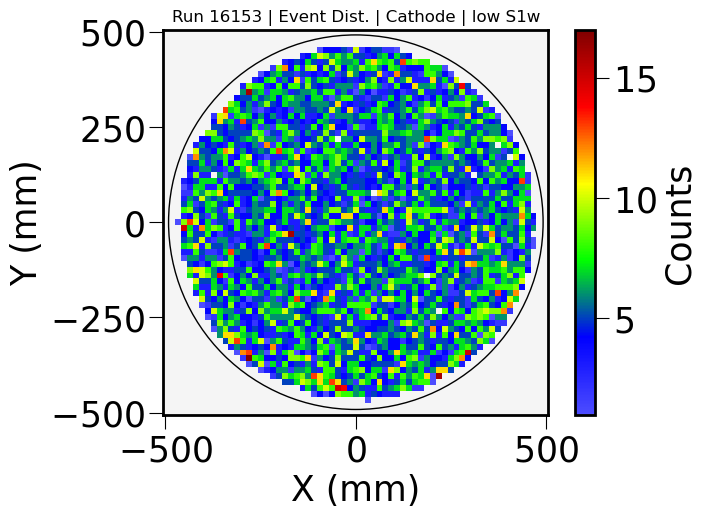

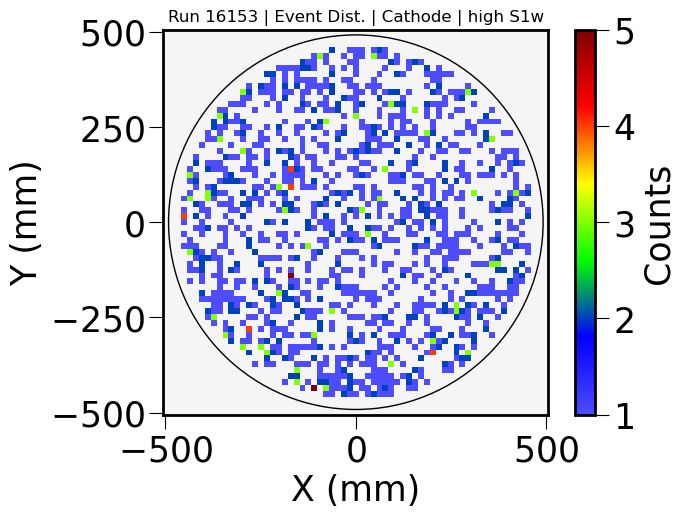

In [65]:
limit_218 = 400e3

for key in SEL_DICT.keys():
    
    run_id = int(key.split('_')[0])

    for width_type in ['low', 'high']:

        temp_df = SEL_DICT[key][width_type + '_df']

        for rad_lim in r_lims:

            # Masking
            mask = (temp_df['DT'] >= cath_lim) & (temp_df['S2e_corr'] >= limit_218)
            # mask = None
            if mask is not None:    mask_df = temp_df[mask]

            # Variables
            X = mask_df['X']
            Y = mask_df['Y']

            # Map
            xy_map, ex, ey = crudo.pt.mapping(X, Y, bin_scale=1, max_limit=crudo.pt.N100_rad, pos=True, norm=False)
            xy_map         = np.ma.masked_where(xy_map==0, xy_map)

            # Plot
            plt.pcolormesh(ex, ey, xy_map.T, cmap=crudo.pt.custom_hsv, shading='auto')
            cbar = plt.colorbar(label='Counts')
            # cbar.set_ticks([0.6, 0.8, 1.0, 1.2, 1.4])
            plt.xlabel('X (mm)')
            plt.ylabel('Y (mm)')
            # plt.title (f'Run {key} | Event Dist.', loc='center', fontsize=12) 
            plt.title (f'Run {key} | Event Dist. | Cathode | {width_type} S1w', loc='center', fontsize=12)

            plt.gca().add_patch(crudo.pt.plot_circle(crudo.pt.N100_rad))
            plt.gca().set_aspect('equal', adjustable='box')
            plt.gca().set_facecolor("whitesmoke")
            # plt.savefig(f'/lhome/ific/c/ccortesp/Analysis/NEXT-100/Cmmssnng/images/events_dist_run_{key}.pdf')
            plt.show()

# Energy Plots

### $S1e$


Run 16114:


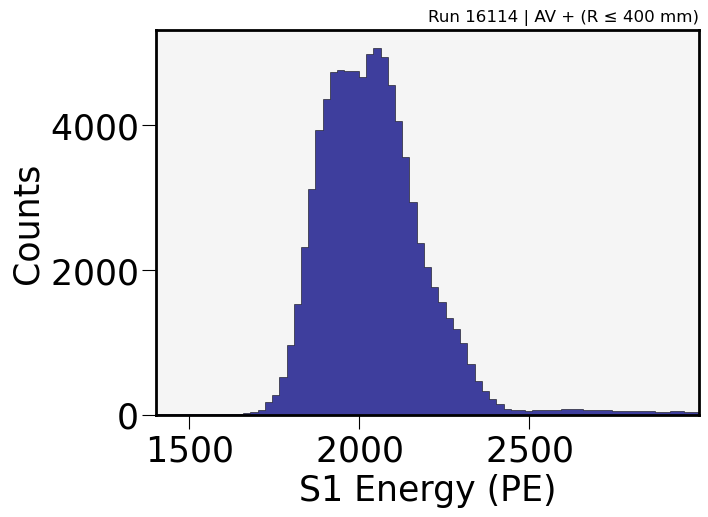


Run 16120:


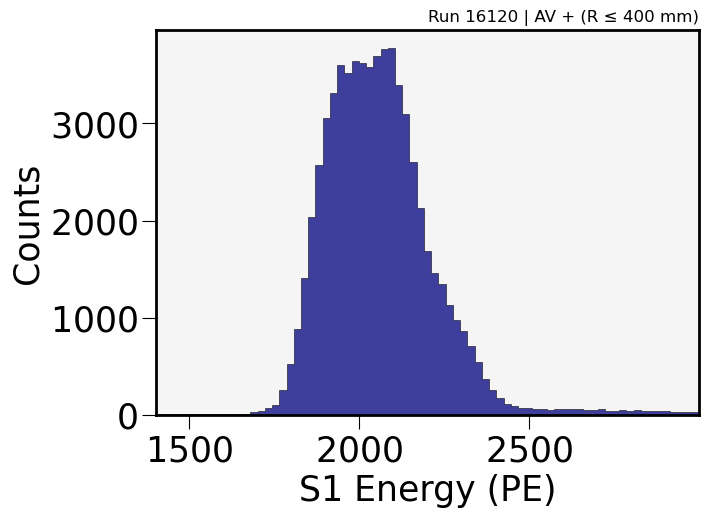

In [20]:
# Params
n_bins = 75
e1_lim  = 3e3
rad_lim = 400
E1_down = 1.8e3;  E1_up = 2.2e3

# Fit?
do_fit = False

for key in SEL_DICT.keys():

    print(f"\nRun {key}:")
    doro_df = SEL_DICT[key]['doro_df']

    # Variables
    E1 = doro_df['S1e_corr']
    DT = doro_df['DT']
    R  = doro_df['R']

    # Masking
    mask = (EXTRA_INFO[key]['alpha_mask']) & (EXTRA_INFO[key]['AV_Z_mask']) & (E1 < e1_lim) & (R <= rad_lim)
    # mask = None
    if mask is not None:
        E1 = E1[mask]

    # Histogram
    E_counts, E_edges = np.histogram(E1, bins=n_bins)
    bin_width = np.diff(E_edges).mean()

    plt.stairs(E_counts, E_edges, 
               fill=True, color=crudo.pt.hist_colors[5], alpha=0.75, lw=0.5, ec='black')

    # --- Fit
    if do_fit:

        # Filter the data for the fit
        fit_region_mask =  (E1 >= E1_down) & (E1 <= E1_up)
        E1_fit = E1[fit_region_mask]

        # Compute representative values for the fit
        x_centers, x_err, y_centers, y_err = crudo.ff.prefit_1D(E1_fit, bins=E_edges)
        # Filter out points with zero error (bins with 1 event)
        valid_points = y_err > 0
        x_fit = x_centers[valid_points];      x_fit_err = x_err[valid_points]
        y_fit = y_centers[valid_points];     y_fit_err = y_err[valid_points]

        # Definte the cost function + initial guess
        least_squares = LeastSquares(x_fit, y_fit, y_fit_err, crudo.ff.gauss_func)
        init_guess = [y_fit.max(), x_fit.min(), bin_width]

        # Define the Minuit object
        m = Minuit(least_squares, *init_guess)

        # Minimization process of the cost function and error estimation
        m.migrad()
        m.hesse()

        # Results
        popt = m.values;  perr = m.errors
        print(f'Fit: m = ({popt[0]:.2f} ± {perr[0]:.2f}) PE/μs, b = ({popt[1]:.2f} ± {perr[1]:.2f}) PE')    
        # FIT_PARAMETERS[key]["S1e"] = {"m_CV": popt[0], "m_err": perr[0], "b_CV": popt[1], "b_err": perr[1]}

        # Reduced chi-square
        chi2 = m.fval
        ndof = len(x_fit) - m.nfit
        print(f"     χ² / ndof = {chi2 / ndof:.2f}")

        # Plot data points only for the valid fit region
        plt.errorbar(x_fit, y_fit, xerr=x_fit_err, yerr=y_fit_err, 
                    fmt='o', ms=2, c='black', ecolor='black', elinewidth=0.5)

        # Plot fit line
        # if fit_success:
        fit_y = crudo.ff.gauss_func(x_centers, *popt)
        plt.plot(x_centers, fit_y, color="red")
        # else:
        #     guess_y = crudo.ff.bigauss_func(E_centers, *popt)
        #     plt.plot(E_centers, guess_y, color="orange", ls="--", label="Failed Guess")

    else:   pass

    # --- Styling
    plt.xlabel('S1 Energy (PE)')
    plt.ylabel('Counts')
    plt.xlim(E_edges[0], E_edges[-1])
    # plt.xlim(E1_down, E1_up)
    # plt.yscale('log')
    # plt.ticklabel_format(axis='x', style='sci', scilimits=(3, 3))
    plt.title (f'Run {key} | AV + (R ≤ {rad_lim} mm)', loc='right', fontsize=12)

    plt.gca().set_facecolor("whitesmoke")
    # plt.savefig(f'/lhome/ific/c/ccortesp/Analysis/NEXT-100/Cmmssnng/images/S2e_corr_run_{key}.pdf')
    plt.show()

### $S2e$


Run 14739:
  - S2 Energy = [41691.88, 2262283.69] PE


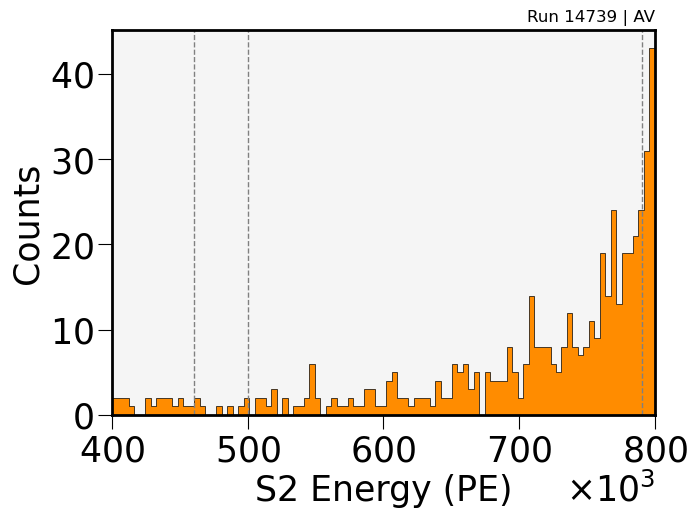


Run 16123:
  - S2 Energy = [40475.57, 1150306.13] PE


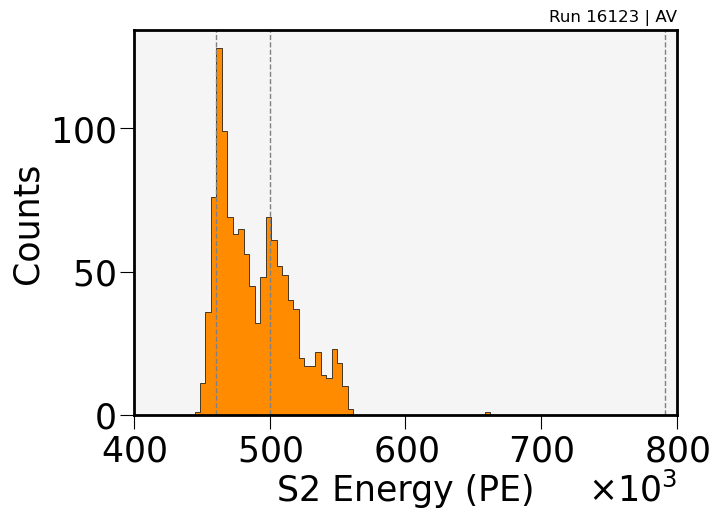

In [83]:
# Params
# n_bins = 100
rad_lim = 100
E_min = 400e3
E_max = 800e3
n_bins = np.linspace(E_min, E_max, 100)

# Fit?
do_fit = False

for key in SEL_DICT.keys():

    print(f"\nRun {key}:")
    doro_df = SEL_DICT[key]['doro_df']

    # Variables
    E2 = doro_df['S2e_corr']
    DT = doro_df['DT']
    R  = np.sqrt(doro_df['X']**2 + doro_df['Y']**2)
    print(f"  - S2 Energy = [{E2.min():.2f}, {E2.max():.2f}] PE")

    # Masking
    mask = (EXTRA_INFO[key]['alpha_mask']) & (EXTRA_INFO[key]['AV_Z_mask']) & (R <= rad_lim) & (doro_df['S1w'] >= 500)
    # mask = None
    if mask is not None:
        E2 = E2[mask]

    # Histogram
    E_counts, E_edges = np.histogram(E2, bins=n_bins)
    bin_width = np.diff(E_edges).mean()

    plt.stairs(E_counts, E_edges, 
               fill=True, color=crudo.pt.hist_colors[2], alpha=1.0, lw=0.5, ec='black')

    # --- Fit
    if do_fit:

        # Compute representative values for the entire histogram
        E_centers, x_errors, E_values, y_errors = crudo.ff.prefit_1D(E2, E_edges)

        # Apply both the E_min/E_max region AND the valid error filter simultaneously
        valid_mask = (y_errors > 0) & (E_centers >= E_min) & (E_centers <= E_max)
        x_fit = E_centers[valid_mask];  x_err_fit = x_errors[valid_mask]
        y_fit = E_values[valid_mask];   y_err_fit = y_errors[valid_mask]

        sigma_guess = 4 * bin_width
        p0 = [1.0, 600e3, sigma_guess, 1.0, 800e3, sigma_guess]
        print(f'Initial values: {np.round(p0, 2)}')

        # We force sigma > 0.001 to guarantee it is strictly positive.
        lower_bounds = [0, E_min, 0.001, 0, E_min, 0.001]
        upper_bounds = [np.inf, E_max, np.inf, np.inf, E_max, np.inf]

        # --- Fit
        try:
            popt, pcov = curve_fit( crudo.ff.bigauss_func, x_fit, y_fit
                                , p0=p0, bounds=(lower_bounds, upper_bounds), maxfev=10000 )
            
            # Ensure peak 1 is always the lower energy peak
            # curve_fit sometimes swaps the parameters. If mu1 > mu2, we swap them back.
            if popt[1] > popt[4]:
                popt = [popt[3], popt[4], popt[5], popt[0], popt[1], popt[2]]  
            print(f'Final values: {np.round(popt, 2)}') 
            
            # --- Energy Resolution
            FWHM = 2.355 * abs(popt[2]) 
            e_res = (FWHM / popt[1]) * 100
            EXTRA_INFO[key]['e_resolution'] = e_res
            print(f'Energy resolution (Rn-peak): {e_res:.2f}%')

            fit_success = True

        except RuntimeError:
            print(f'Fit FAILED')
            EXTRA_INFO[key]['e_resolution'] = None
            popt = p0
            fit_success = False
    
        # Plot data points only for the valid fit region
        plt.errorbar(x_fit, y_fit, xerr=x_err_fit, yerr=y_err_fit, 
                    fmt='o', ms=2, c='black', ecolor='black', elinewidth=0.5)

        # Plot fit line
        if fit_success:
            fit_y = crudo.ff.bigauss_func(E_centers, *popt)
            plt.plot(E_centers, fit_y, color="red", label=f"Fit (Res: {e_res:.2f}%)")
        else:
            guess_y = crudo.ff.bigauss_func(E_centers, *popt)
            plt.plot(E_centers, guess_y, color="orange", ls="--", label="Failed Guess")

    else:   pass

    # --- Styling
    plt.xlabel('S2 Energy (PE)')
    plt.ylabel('Counts')
    plt.xlim(E_edges[0], E_edges[-1])
    # plt.xlim(E_min, E_max)
    # plt.yscale('log')
    plt.ticklabel_format(axis='x', style='sci', scilimits=(3, 3))
    # plt.title (f'Run {key} | AV + (R ≤ {rad_lim} mm)', loc='right', fontsize=12)
    plt.title (f'Run {key} | AV', loc='right', fontsize=12)

    # Lines
    plt.axvline(x=460e3, c='gray', ls='--', lw=1)
    plt.axvline(x=500e3, c='gray', ls='--', lw=1)



    plt.axvline(x=791e3, c='gray', ls='--', lw=1)
    plt.axvline(x=872e3, c='gray', ls='--', lw=1)
    plt.axvline(x=909e3, c='gray', ls='--', lw=1)
    plt.axvline(x=1109e3, c='gray', ls='--', lw=1)

    plt.gca().set_facecolor("whitesmoke")
    # plt.savefig(f'/lhome/ific/c/ccortesp/Analysis/NEXT-100/Cmmssnng/images/S2e_corr_run_{key}.pdf')
    plt.show()

In [77]:
test_df = SEL_DICT['16123']['doro_df'].copy()
test_df = test_df[(test_df['S2e_corr'] >= 450e3) & (test_df['S2e_corr'] <= 470e3) & (test_df['R'] <= 100)]
test_df

,event,time,s1_peak,s2_peak,nS1,nS2,S1w,S1h,S1e,S1t,...,R,Phi,Xrms,Yrms,S1e_corr,S2e_corr_LT,x_bin,y_bin,S2e_norm_factor,S2e_corr
90,235621,1.791979e+09,0,0,1,1,575.0,316.823730,1985.831299,344425.0,...,82.968827,1.529919,31.116495,29.733871,2122.606438,462818.408019,8,9,1.006202,459965.699320
685,131706,1.791976e+09,0,0,1,1,350.0,274.927521,1644.011719,772750.0,...,96.734847,-2.611342,26.037423,25.737893,2082.007031,473812.449100,7,7,1.018712,465109.303908
2419,202308,1.791978e+09,0,0,1,1,350.0,342.859161,2015.464600,135325.0,...,48.844142,2.953328,30.140317,30.278159,2002.172397,471945.800211,7,8,1.017204,463963.706470
3120,14897,1.791973e+09,0,0,1,1,350.0,270.903717,1630.528564,676950.0,...,61.859577,-0.906506,25.050384,25.098464,1983.971549,476742.149400,9,7,1.035724,460298.333296
3498,78716,1.791975e+09,0,0,1,1,375.0,291.828400,1807.097656,579075.0,...,80.478637,1.103763,28.053590,25.724707,2112.427887,465405.155322,9,9,1.018524,456940.579189
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
219306,200221,1.791978e+09,0,0,1,1,625.0,221.192017,1375.861816,1084650.0,...,39.474006,-1.727575,23.088435,25.168637,2016.642764,470132.949504,8,7,1.016187,462644.201738
219431,116893,1.791976e+09,0,0,1,1,625.0,223.639191,1358.454834,1249525.0,...,56.074200,2.484973,24.440834,25.796405,2170.495924,468493.161298,7,9,1.001934,467588.844594
219991,48237,1.791974e+09,0,0,1,1,350.0,303.652679,1825.040405,432000.0,...,95.732714,-2.013355,24.950219,24.253186,2014.855250,478779.137516,7,7,1.018712,469984.762534
220082,223755,1.791979e+09,0,0,1,1,800.0,268.981964,1673.777588,757300.0,...,64.713716,2.554858,28.163466,29.201961,2105.700876,468700.097185,7,9,1.001934,467795.381040



Run 14739:


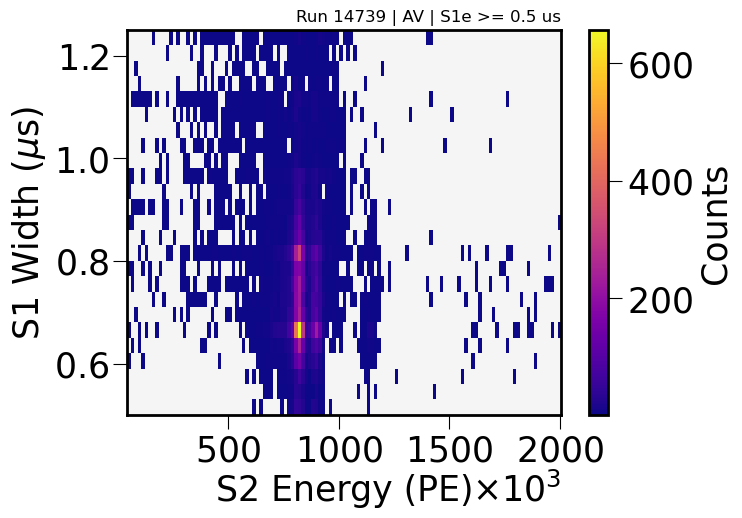


Run 16123:


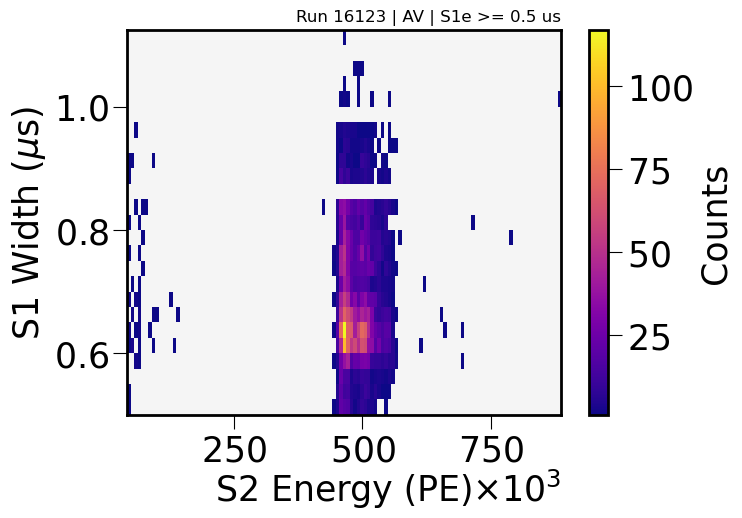

In [100]:
# n_bins = 50
for key in SEL_DICT.keys():

    print(f"\nRun {key}:")
    doro_df = SEL_DICT[key]['doro_df']

    # Variables    
    W1 = doro_df['S1w'] / 1e3
    E2c = doro_df['S2e_corr']
    R = doro_df['R']
    # R = np.sqrt(doro_df['X']**2 + doro_df['Y']**2)

    # Masking
    mask = (EXTRA_INFO[key]['AV_Z_mask']) & (EXTRA_INFO[key]['alpha_mask']) & (W1 >= 0.5) & (R <= 200)
    # mask = None
    if mask is not None:
        W1 = W1[mask]
        E2c = E2c[mask]

    # 2D Histogram
    s1w_s2e_map, ex, ey = np.histogram2d(E2c, W1, bins=[125, 25])
    s1w_s2e_map         = np.ma.masked_where(s1w_s2e_map==0, s1w_s2e_map)

    # Plot
    plt.pcolormesh(ex, ey, s1w_s2e_map.T, cmap='plasma', shading='auto')
    plt.colorbar(label='Counts')
    plt.xlabel('S2 Energy (PE)')
    plt.ylabel('S1 Width ($\mu$s)')
    # plt.xlim(0, 300e3)
    # plt.ylim(0, 200)
    plt.ticklabel_format(axis='x', style='sci', scilimits=(3, 3))
    plt.title (f'Run {key} | AV | S1e >= {W1.min()} us', loc='right', fontsize=12)

    # Lines
    # plt.axvline(x=25e3, c='gray', ls='--', lw=1.5)
    # plt.axhline(y=12e3, c='black', ls='--', lw=1.5)

    plt.gca().set_facecolor("whitesmoke")
    plt.show()


Run 14739:


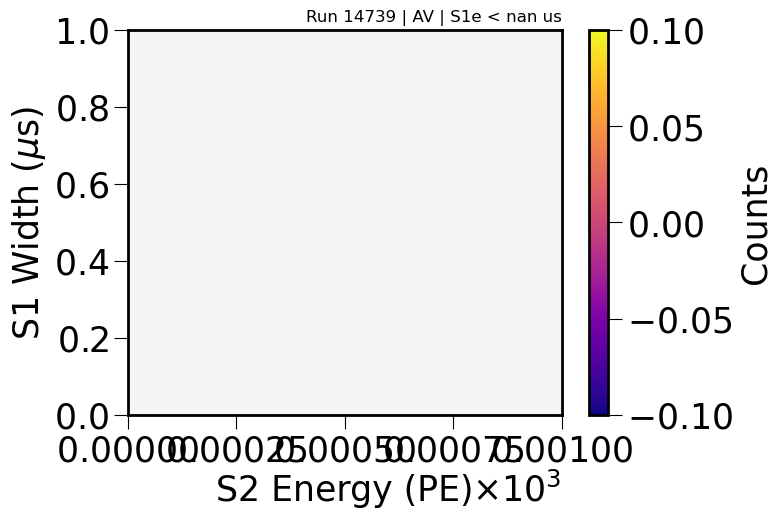


Run 16123:


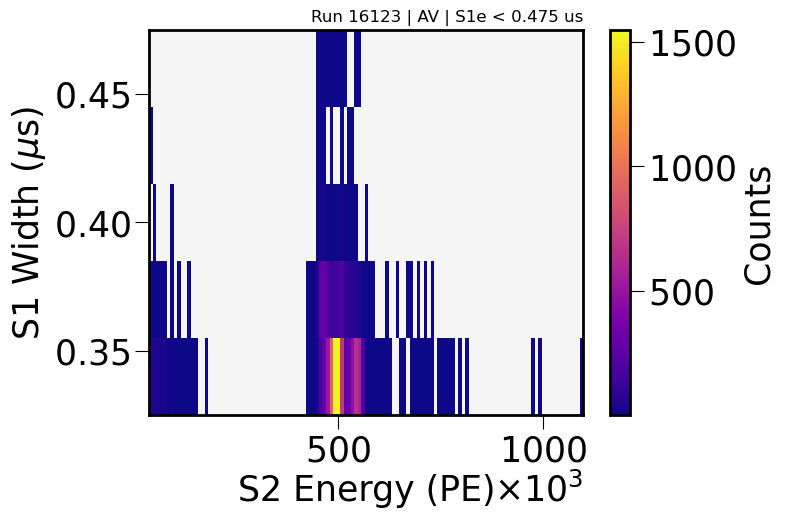

In [103]:
# n_bins = 50
for key in SEL_DICT.keys():

    print(f"\nRun {key}:")
    doro_df = SEL_DICT[key]['doro_df']

    # Variables    
    W1 = doro_df['S1w'] / 1e3
    E2c = doro_df['S2e_corr']
    R = doro_df['R']
    # R = np.sqrt(doro_df['X']**2 + doro_df['Y']**2)

    # Masking
    mask = (EXTRA_INFO[key]['AV_Z_mask']) & (EXTRA_INFO[key]['alpha_mask']) & (W1 < 0.5) & (R <= 200)
    # mask = None
    if mask is not None:
        W1 = W1[mask]
        E2c = E2c[mask]

    # 2D Histogram
    s1w_s2e_map, ex, ey = np.histogram2d(E2c, W1, bins=[125, 5])
    s1w_s2e_map         = np.ma.masked_where(s1w_s2e_map==0, s1w_s2e_map)

    # Plot
    plt.pcolormesh(ex, ey, s1w_s2e_map.T, cmap='plasma', shading='auto')
    plt.colorbar(label='Counts')
    plt.xlabel('S2 Energy (PE)')
    plt.ylabel('S1 Width ($\mu$s)')
    # plt.xlim(0, 300e3)
    # plt.ylim(0, 200)
    plt.ticklabel_format(axis='x', style='sci', scilimits=(3, 3))
    plt.title (f'Run {key} | AV | S1e < {W1.max()} us', loc='right', fontsize=12)

    # Lines
    # plt.axvline(x=25e3, c='gray', ls='--', lw=1.5)
    # plt.axhline(y=12e3, c='black', ls='--', lw=1.5)

    plt.gca().set_facecolor("whitesmoke")
    plt.show()


Run 16105:
  - S2 Energy = [40027.68, 1654431.59] PE

Run 16114:
  - S2 Energy = [39578.91, 2650086.58] PE

Run 16116:
  - S2 Energy = [40380.37, 2771893.94] PE

Run 16120:
  - S2 Energy = [39626.54, 3002106.53] PE


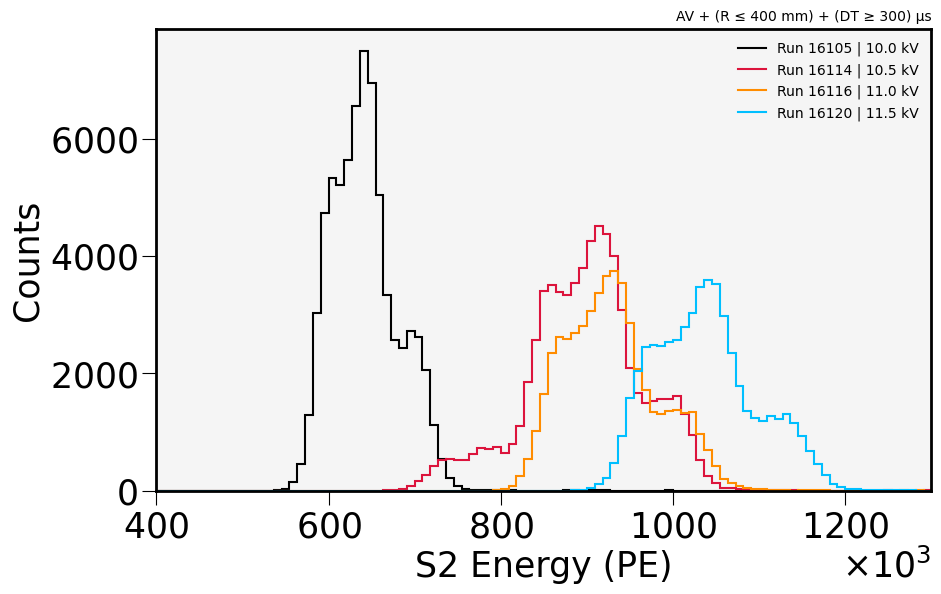

In [42]:
# Params
rad_lim = 400
dt_lim = 300
E_min = 400e3
E_max = 1300e3
n_bins = np.linspace(E_min, E_max, 100)

plt.figure(figsize=(10, 6))

for i, key in enumerate(SEL_DICT.keys()):

    print(f"\nRun {key}:")
    doro_df = SEL_DICT[key]['doro_df']
    gate_volt = RUNS_INFO_DF.loc[RUNS_INFO_DF['run_number'] == int(key.split('_')[0]), 'gate_voltage'].values[0] / 1e3

    # Variables
    E2 = doro_df['S2e_corr']
    DT = doro_df['DT']
    R  = np.sqrt(doro_df['X']**2 + doro_df['Y']**2)
    print(f"  - S2 Energy = [{E2.min():.2f}, {E2.max():.2f}] PE")

    # Masking
    mask = (EXTRA_INFO[key]['alpha_mask']) & (EXTRA_INFO[key]['AV_Z_mask']) & (R <= rad_lim) & (DT >= dt_lim)
    # mask = None
    if mask is not None:
        E2 = E2[mask]

    # Histogram
    E_counts, E_edges = np.histogram(E2, bins=n_bins)
    bin_width = np.diff(E_edges).mean()

    plt.stairs(E_counts, E_edges, 
               fill=False, lw=1.5, ec=crudo.pt.hist_colors[i], label=f'Run {key} | {gate_volt:.1f} kV')

# --- Styling
plt.xlabel('S2 Energy (PE)')
plt.ylabel('Counts')
plt.xlim(E_edges[0], E_edges[-1])
# plt.xlim(E_min, E_max)
# plt.yscale('log')
plt.ticklabel_format(axis='x', style='sci', scilimits=(3, 3))
plt.title (f'AV + (R ≤ {rad_lim} mm) + (DT ≥ {dt_lim}) μs', loc='right', fontsize=10)
plt.legend(loc='upper right', fontsize=10, facecolor='none')

# Lines
# plt.axvline(x=625e3, c='gray', ls='--', lw=1)

plt.gca().set_facecolor("whitesmoke")
# plt.savefig(f'/lhome/ific/c/ccortesp/Analysis/NEXT-100/Cmmssnng/images/S2e_corr_run_{key}.pdf')
plt.show()

### Active Volume


Run 16114:


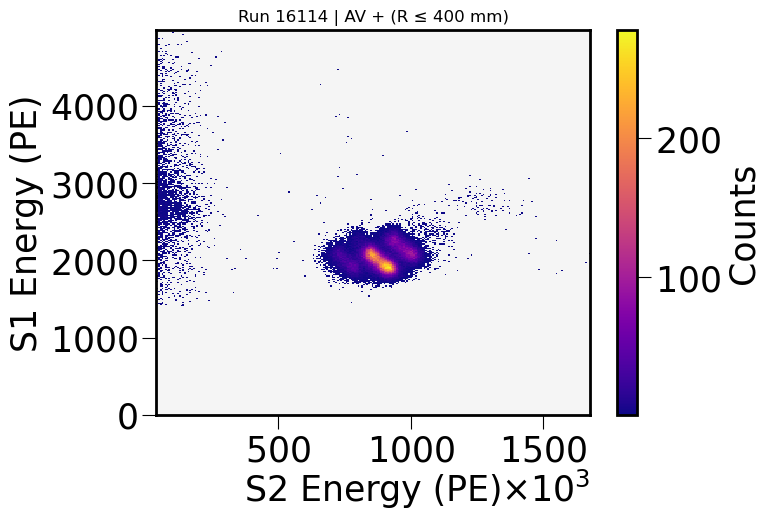


Run 16120:


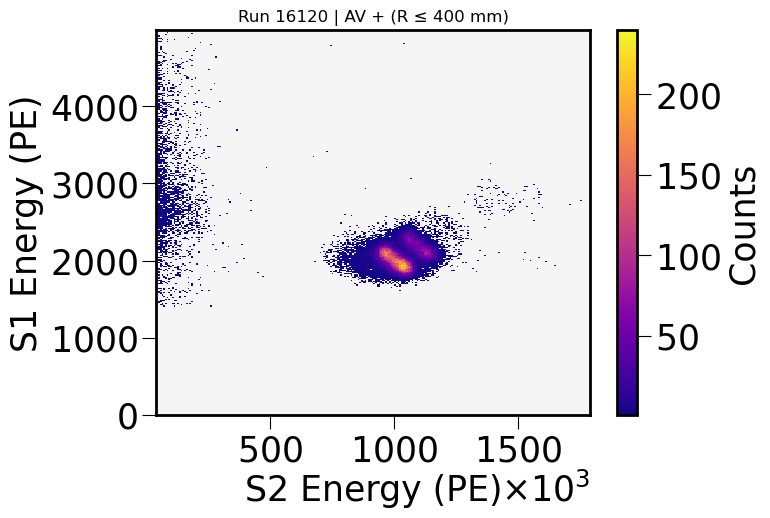

In [24]:
# Global
n_bins = 250
# rad_lim = [500, 400, 300, 200]
rad_lim = [400]
e1_lim  = 5e3

for key in SEL_DICT.keys():

    print(f"\nRun {key}:")
    doro_df = SEL_DICT[key]['doro_df']

    # Variables    
    E1 = doro_df['S1e_corr']
    E2 = doro_df['S2e_corr']
    R = np.sqrt(doro_df['X']**2 + doro_df['Y']**2)

    for r_lim in rad_lim:

        # Masking
        mask = (EXTRA_INFO[key]['alpha_mask']) & (EXTRA_INFO[key]['AV_Z_mask']) & (R <= r_lim) & (E1 <= e1_lim)
        E1_mask = E1[mask]
        E2_mask = E2[mask]

        # 2D Histogram
        s1e_s2e_map, ex, ey = np.histogram2d(E2_mask, E1_mask, bins=[n_bins, n_bins])
        s1e_s2e_map         = np.ma.masked_where(s1e_s2e_map==0, s1e_s2e_map)

        # Plot
        plt.pcolormesh(ex, ey, s1e_s2e_map.T, cmap='plasma', shading='auto')
        plt.colorbar(label='Counts')
        plt.xlabel('S2 Energy (PE)')
        plt.ylabel('S1 Energy (PE)')
        # plt.xlim(450e3, 900e3)
        # plt.ylim(0, 4e3)
        plt.ticklabel_format(axis='x', style='sci', scilimits=(3, 3))
        plt.yticks(ticks=np.arange(0, 4001, 1000))
        plt.title (f'Run {key} | AV + (R ≤ {r_lim} mm)', loc='center', fontsize=12) 

        plt.gca().set_facecolor("whitesmoke")
        # plt.savefig(f'/lhome/ific/c/ccortesp/Analysis/NEXT-100/Cmmssnng/images/S2e_S1e__AV_run_{key}.pdf')
        plt.show()

### Cathode


Run 16114:


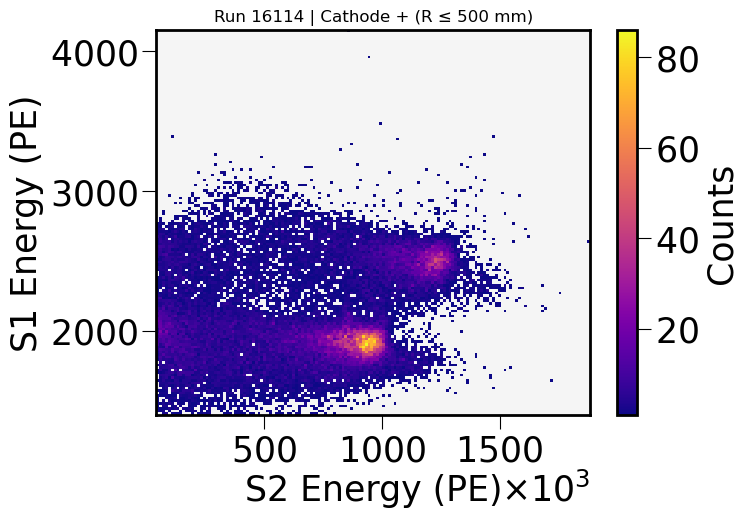


Run 16120:


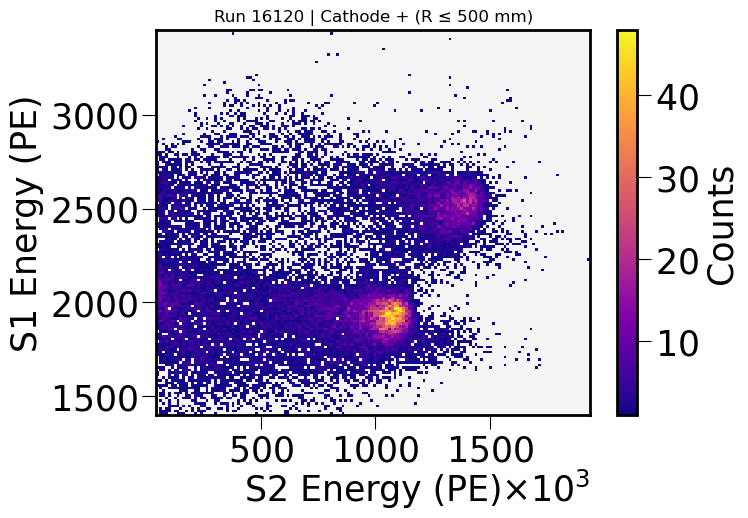

In [26]:
# Global
n_bins = 150
# rad_lim = [500, 400, 300, 200]
rad_lim = [500]
e1_lim  = 5e3

for key in SEL_DICT.keys():

    print(f"\nRun {key}:")
    doro_df = SEL_DICT[key]['doro_df']

    # Variables    
    E1 = doro_df['S1e_corr']
    E2 = doro_df['S2e_corr']
    R = np.sqrt(doro_df['X']**2 + doro_df['Y']**2)

    for r_lim in rad_lim:

        # Masking
        mask = (EXTRA_INFO[key]['alpha_mask']) & (EXTRA_INFO[key]['cath_mask']) & (R <= r_lim) & (E1 <= e1_lim)
        E1_mask = E1[mask]
        E2_mask = E2[mask]

        # 2D Histogram
        s1e_s2e_map, ex, ey = np.histogram2d(E2_mask, E1_mask, bins=[n_bins, n_bins])
        s1e_s2e_map         = np.ma.masked_where(s1e_s2e_map==0, s1e_s2e_map)

        # Plot
        plt.pcolormesh(ex, ey, s1e_s2e_map.T, cmap='plasma', shading='auto')
        plt.colorbar(label='Counts')
        plt.xlabel('S2 Energy (PE)')
        plt.ylabel('S1 Energy (PE)')
        # plt.xlim(300e3, 1000e3)
        # plt.ylim(0, 4e3)
        plt.ticklabel_format(axis='x', style='sci', scilimits=(3, 3))
        plt.title (f'Run {key} | Cathode + (R ≤ {r_lim} mm)', loc='center', fontsize=12) 

        plt.gca().set_facecolor("whitesmoke")
        plt.show()

# Run Stability

## $S2e$ / NSiPM

In [38]:
SEL_DICT['16047_20260727']['doro_df'].columns

Index(['event', 'time', 's1_peak', 's2_peak', 'nS1', 'nS2', 'S1w', 'S1h',
       'S1e', 'S1t', 'S2w', 'S2h', 'S2e', 'S2q', 'S2t', 'qmax', 'Nsipm', 'DT',
       'Z', 'Zrms', 'X', 'Y', 'R', 'Phi', 'Xrms', 'Yrms', 'run_id', 'S1e_corr',
       'S2e_corr_LT', 'x_bin', 'y_bin', 'S2e_norm_factor', 'S2e_corr'],
      dtype='object')


Run 14739:
  S2e / # SiPMs = [1637.63, 11036.41] PE


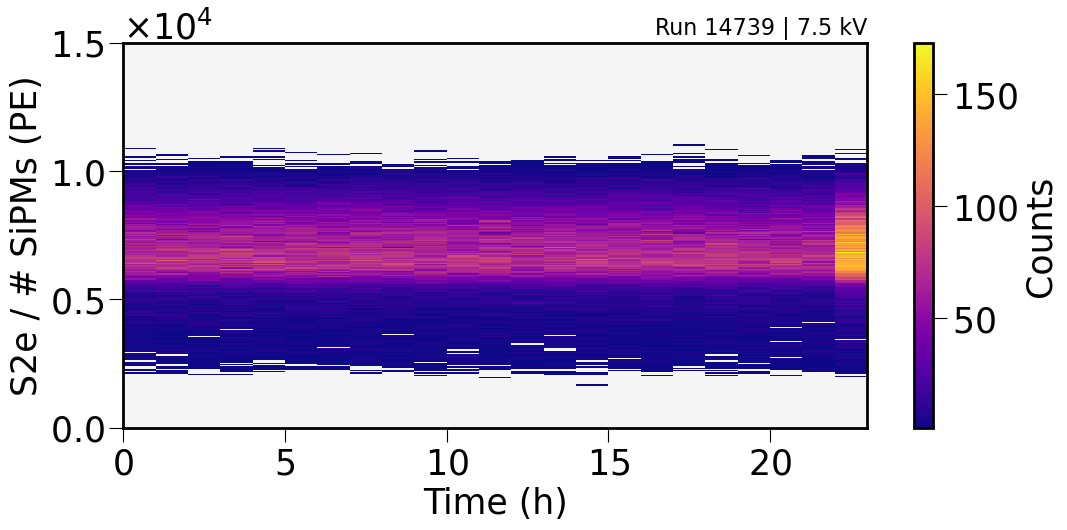


Run 16122:
  S2e / # SiPMs = [762.21, 5989.70] PE


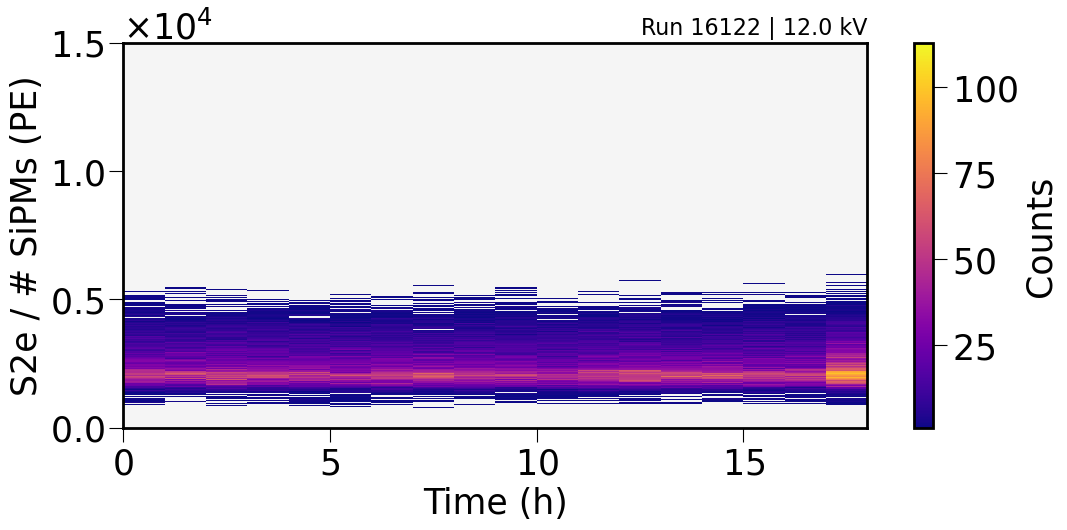


Run 16123:
  S2e / # SiPMs = [1153.81, 5868.49] PE


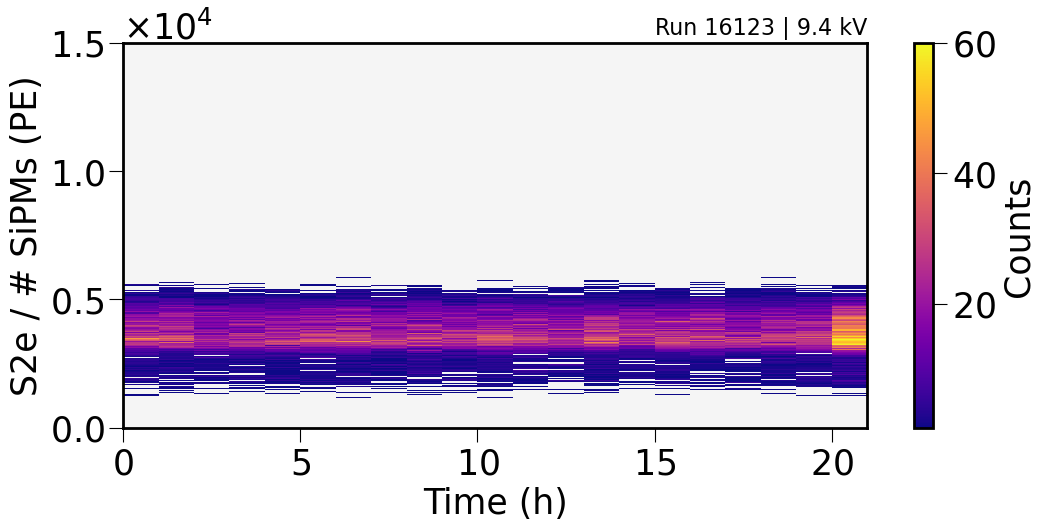

In [27]:
# x_bins = 24  # 24 bins, one for each hour
y_bins = 200

for key in SEL_DICT.keys():

    print(f"\nRun {key}:")
    doro_df = SEL_DICT[key]['doro_df']
    gate_volt = RUNS_INFO_DF.loc[RUNS_INFO_DF['run_number'] == int(key.split('_')[0]), 'gate_voltage'].values[0] / 1e3

    # Variables
    time = doro_df['time'] - doro_df['time'].min()    # Normalize time to start at 0
    time = (time / 3600).astype(int)                # Convert time to hours
    E2     = doro_df['S2e']
    n_sipm = doro_df['Nsipm']

    # Mask
    mask = (n_sipm > 0) 

    time = time[mask]
    E2     = E2[mask]
    n_sipm = n_sipm[mask]

    y_val = E2 / n_sipm
    print(f"  S2e / # SiPMs = [{y_val.min():.2f}, {y_val.max():.2f}] PE")

    # 2D Histogram
    ex = np.arange(time.min(), time.max(), 1.0)
    map_2d, ex, ey = np.histogram2d(time, y_val, bins=[ex, y_bins], range=[None, [y_val.min(), y_val.max()]])
    map_2d         = np.ma.masked_where(map_2d==0, map_2d)

    # Plot
    plt.figure(figsize=(12, 5))
    plt.pcolormesh(ex, ey, map_2d.T, cmap='plasma', shading='auto')
    plt.colorbar(label='Counts')
    plt.xlabel('Time (h)')
    # plt.xticks(ticks=np.arange(0, 25, 2), labels=[f"{i}" for i in range(0, 25, 2)])
    plt.ylabel('S2e / # SiPMs (PE)')
    plt.ylim(0, 15e3)
    plt.ticklabel_format(axis='y', style='sci', scilimits=(-1, 0))
    plt.title (f'Run {key} | {gate_volt:.1f} kV', loc='right', fontsize=16) 

    plt.gca().set_facecolor("whitesmoke")
    plt.show()


Run 16047_20260727:


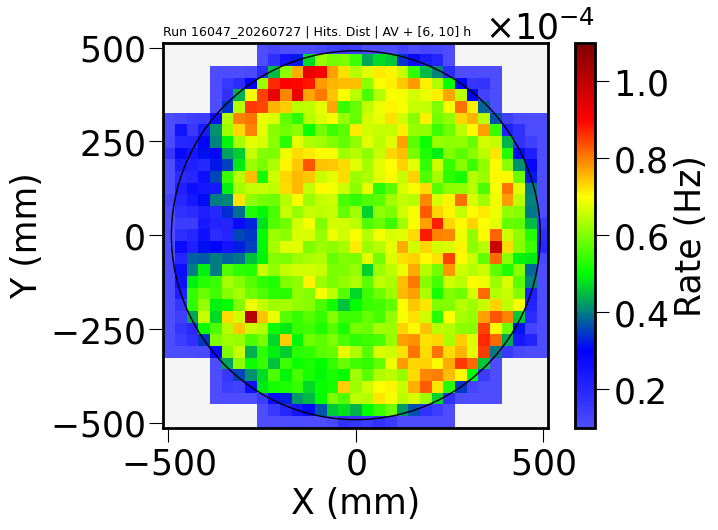


Run 16057_20260727:


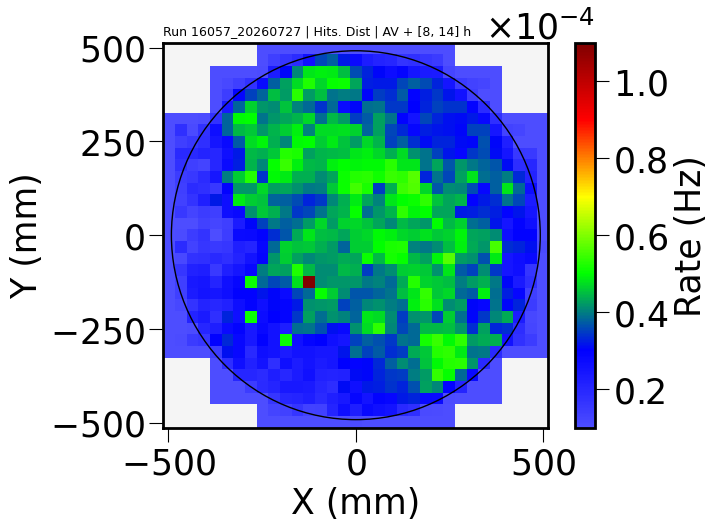

In [59]:
times_47 = [6, 10]
times_57 = [8, 14]

for key in SEL_DICT.keys():

    print(f"\nRun {key}:")
    soph_df = SEL_DICT[key]['soph_df']

    # Variables  
    X = soph_df['X']
    Y = soph_df['Y']
    Z = soph_df['Z']
    time = ((soph_df['time'] - soph_df['time'].min()) / 3600).astype(int)

    if   key == '16047_20260727': t_min, t_max = times_47
    elif key == '16057_20260727': t_min, t_max = times_57

    # Masking
    mask = (Z >= 0) & (Z <= EXTRA_INFO[key]['cath_lim']) & (time >= t_min) & (time <= t_max)
    X_mask = X[mask]
    Y_mask = Y[mask]

    # Map
    xy_map, ex, ey = crudo.pt.mapping(X_mask, Y_mask, bin_scale=2, max_limit=crudo.pt.N100_rad, pos=True, norm=True)
    xy_map = xy_map / ((t_max - t_min) * 3600)      # Normalize by time interval to get rate
    xy_map = np.ma.masked_where(xy_map==0, xy_map)

    # Plot
    plt.pcolormesh(ex, ey, xy_map.T, cmap=crudo.pt.custom_hsv, shading='auto', vmin=0.1e-4, vmax=1.1e-4)
    plt.colorbar(label='Rate (Hz)', shrink=1.0)
    plt.xlabel('X (mm)')
    plt.ylabel('Y (mm)')
    plt.title (f'Run {key} | Hits. Dist | AV + [{t_min}, {t_max}] h', loc='left', fontsize=9) 

    plt.gca().add_patch(crudo.pt.plot_circle(crudo.pt.N100_rad))
    plt.gca().set_aspect('equal', adjustable='box')
    plt.gca().set_facecolor("whitesmoke")
    plt.show()

## Lifetime

In [118]:
# Global
Date      = []
Date_err  = []
Lifet     = []
Lifet_err = []
Lyield    = []
Lyield_err     = []
Run_number = []

def const_func(x, b):
    return crudo.ff.linear_func(x, 0, b)


for key in SEL_DICT.keys():

    print(f"Run {key}:")
    doro_df = SEL_DICT[key]['doro_df']

    Run_number.append(key)

    # Variables
    Time = doro_df['time']

    # Mean date + error for each run
    date_CV    = Time.mean()
    Date.append(date_CV)
    date_error = Time.sem()
    Date_err.append(date_error)

    # Retrieve lifetime fit value   
    LT_CV    = FIT_PARAMETERS[key]["S2e"]["tau_CV"]  / 1e3     # In [ms]
    Lifet.append(LT_CV)
    LT_error = FIT_PARAMETERS[key]["S2e"]["tau_err"] / 1e3
    Lifet_err.append(LT_error)

    #
    LY_CV    = FIT_PARAMETERS[key]["S2e"]["N0_CV"]  # In [PE/μs]
    Lyield.append(LY_CV)
    LY_error = FIT_PARAMETERS[key]["S2e"]["N0_err"]
    Lyield_err.append(LY_error)

    
    

Run 16103:
Run 16104:
Run 16105:


In [115]:
FIT_PARAMETERS

{'16103': {'S1e': {'m_CV': 0.6799226964665488,
   'm_err': 0.0018216639740884148,
   'b_CV': 1041.490920472767,
   'b_err': 1.5219338269503007},
  'S2e': {'N0_CV': 644230.8797011332,
   'N0_err': 525.3620892261587,
   'tau_CV': 32516.541604990995,
   'tau_err': 993.0641541494789}},
 '16104': {'S1e': {'m_CV': 0.6782881041061506,
   'm_err': 0.0018689511473911462,
   'b_CV': 1039.9055578227953,
   'b_err': 1.538204026718317},
  'S2e': {'N0_CV': 643648.76776812,
   'N0_err': 511.8153650933478,
   'tau_CV': 31770.475327364507,
   'tau_err': 941.781561090721}},
 '16105': {'S1e': {'m_CV': 0.6764491279190805,
   'm_err': 0.0018857356057837885,
   'b_CV': 1038.889381105229,
   'b_err': 1.5904297884443868},
  'S2e': {'N0_CV': 642118.4002646587,
   'N0_err': 517.0051705699576,
   'tau_CV': 32160.371923613184,
   'tau_err': 963.9431226951505}}}

No handles with labels found to put in legend.


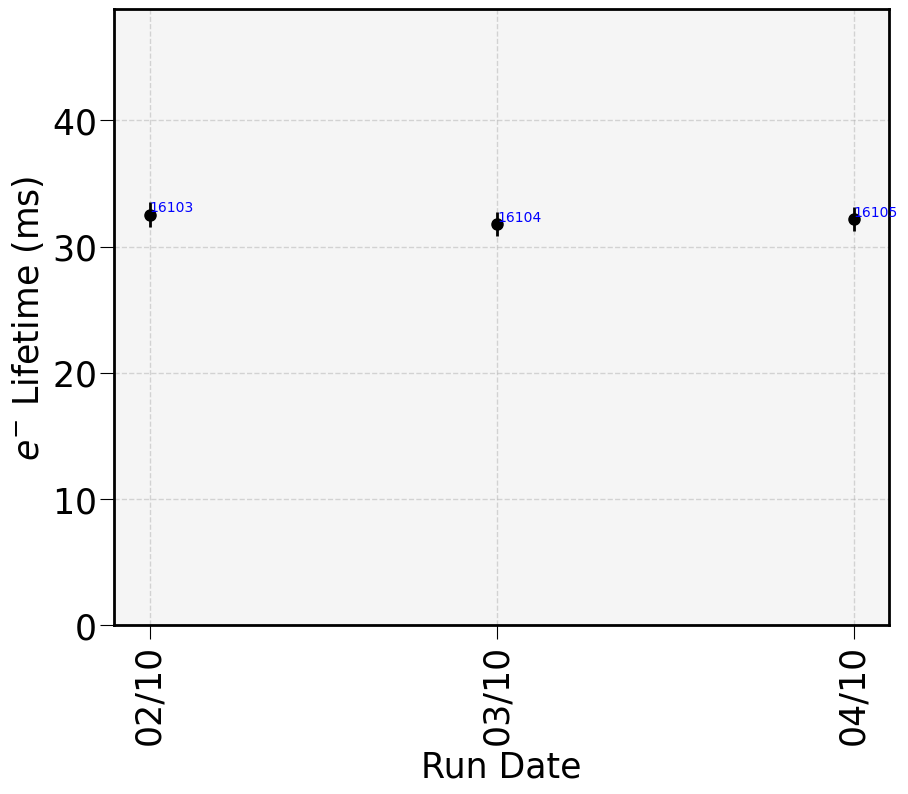

In [120]:
# ----- Plotting ----- #
# plt.figure(figsize=(10, 5))
# Data
plt.errorbar(Date, Lifet, xerr=Date_err, yerr=Lifet_err, fmt='o', c='black', ecolor='black', zorder=2)
for x, y, run_id in zip(Date, Lifet, Run_number):
    plt.text(x, y, str(run_id), fontsize=10, ha='left', va='bottom', color='blue')  # Run number near the point

# Fits
# plt.plot(x_fit[0], y_fit[0], color='blue', ls='-', lw=1.5, label=f'Constant Fit\nχ² / ndof = {chi2[0] / ndof[0]:.2f}', zorder=3)
# plt.plot(x_fit[1], y_fit[1], color='orange', ls='--', label=f'Linear Fit\nχ² / ndof = {chi2[1] / ndof[1]:.2f}')

# Important dates
# plt.axvline(x=1737975600, c='red', ls='--', lw=1.0)
# plt.text(1738030000-1e4, 2.5, 'Hot-getter', fontsize=12, c='red', va='bottom',  ha='right',  rotation=90)

# ----- Styling ----- #
plt.xlabel('Run Date')
x_labels = [crudo.ut.epoch_converter(t, h=False) for t in Date]  # Convert x-axis bin edges to readable time format
plt.xticks(Date, x_labels, rotation=90, ha='center')
plt.ylim(0, 1.5 * max(Lifet))
plt.ylabel(r'$e^{-}$ Lifetime (ms)')
# plt.title(r'$e^{-}$ Lifetime Evolution')
plt.legend(loc='upper right', fontsize=12, facecolor='none')

plt.grid(True)
plt.gca().set_facecolor("whitesmoke")
# plt.savefig(f'/lhome/ific/c/ccortesp/Analysis/NEXT-100/Radon_LPR/images/Lifetime_Evolution.pdf')
# plt.savefig(f'/lhome/ific/c/ccortesp/Analysis/NEXT-100/Rn_analysis/images/Lifetime_Evolution.pdf')
plt.show()

## Light Yield

No handles with labels found to put in legend.


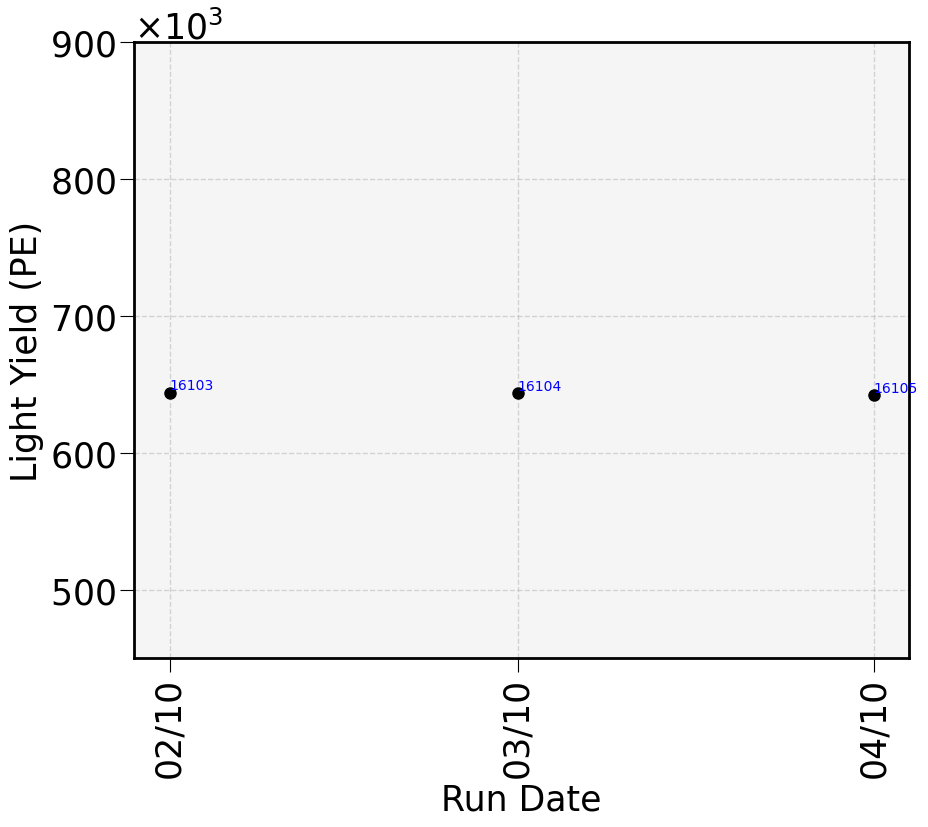

In [151]:
# ----- Plotting ----- #
# plt.figure(figsize=(10, 5))
# Data
plt.errorbar(Date, Lyield, xerr=Date_err, yerr=Lyield_err, fmt='o', c='black', ecolor='black', zorder=2)
for x, y, run_id in zip(Date, Lyield, Run_number):
    plt.text(x, y, str(run_id), fontsize=10, ha='left', va='bottom', color='blue')  # Run number near the point

# Fits
# plt.plot(x_fit[0], y_fit[0], color='blue', ls='-', lw=1.5, label=f'Constant Fit\nχ² / ndof = {chi2[0] / ndof[0]:.2f}', zorder=3)
# plt.plot(x_fit[1], y_fit[1], color='orange', ls='--', label=f'Linear Fit\nχ² / ndof = {chi2[1] / ndof[1]:.2f}')

# Important dates
# plt.axvline(x=1737975600, c='red', ls='--', lw=1.0)
# plt.text(1738030000-1e4, 2.5, 'Hot-getter', fontsize=12, c='red', va='bottom',  ha='right',  rotation=90)

# ----- Styling ----- #
plt.xlabel('Run Date')
x_labels = [crudo.ut.epoch_converter(t, h=False) for t in Date]  # Convert x-axis bin edges to readable time format
plt.xticks(Date, x_labels, rotation=90, ha='center')
plt.ylim(450e3, 900e3)
plt.ylabel(r'Light Yield (PE)')
# plt.title(r'$e^{-}$ Lifetime Evolution')
plt.legend(loc='upper right', fontsize=12, facecolor='none')
plt.ticklabel_format(axis='y', style='sci', scilimits=(3, 3))

plt.grid(True)
plt.gca().set_facecolor("whitesmoke")
# plt.savefig(f'/lhome/ific/c/ccortesp/Analysis/NEXT-100/Radon_LPR/images/Lifetime_Evolution.pdf')
# plt.savefig(f'/lhome/ific/c/ccortesp/Analysis/NEXT-100/Rn_analysis/images/Lifetime_Evolution.pdf')
plt.show()

In [143]:
FIT_PARAMETERS

{'16103': {'S1e': {'m_CV': 0.6799226964665488,
   'm_err': 0.0018216639740884148,
   'b_CV': 1041.490920472767,
   'b_err': 1.5219338269503007},
  'S2e': {'N0_CV': 644230.8797011332,
   'N0_err': 525.3620892261587,
   'tau_CV': 32516.541604990995,
   'tau_err': 993.0641541494789}},
 '16104': {'S1e': {'m_CV': 0.6782881041061506,
   'm_err': 0.0018689511473911462,
   'b_CV': 1039.9055578227953,
   'b_err': 1.538204026718317},
  'S2e': {'N0_CV': 643648.76776812,
   'N0_err': 511.8153650933478,
   'tau_CV': 31770.475327364507,
   'tau_err': 941.781561090721}},
 '16105': {'S1e': {'m_CV': 0.6764491279190805,
   'm_err': 0.0018857356057837885,
   'b_CV': 1038.889381105229,
   'b_err': 1.5904297884443868},
  'S2e': {'N0_CV': 642118.4002646587,
   'N0_err': 517.0051705699576,
   'tau_CV': 32160.371923613184,
   'tau_err': 963.9431226951505}}}